#Deep Learning para visión de computadoras

**Unidad 2.** Detección de objetos, segmentación y secuencias visuales
**2.1** Detección de objetos
**2.4** Análisis de movimiento en video

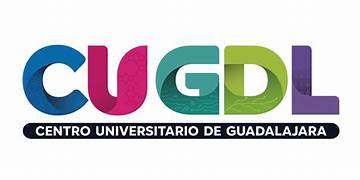

**INSTRUCCIONES**

**Antes de empezar:** `Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)`.

> 📝 Las celdas marcadas con

**✍️ RESPONDE** se contestan *en el propio notebook*

**🔧 AJUSTA** piden modificar parámetros y volver a correr.

## 0. Preparación del entorno

In [1]:
# Dependencias gestionadas con uv (ver pyproject.toml / uv.lock):
#   uv add ultralytics pandas shapely nbconvert
# En Google Colab usa en su lugar:  !pip install -q ultralytics


In [2]:
import os, time, base64, subprocess, shutil, warnings
from collections import Counter, defaultdict
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, ultralytics
from ultralytics import YOLO, solutions
from ultralytics.utils.downloads import safe_download
from IPython.display import HTML, display
import logging
from ultralytics.utils import LOGGER
warnings.filterwarnings("ignore")
LOGGER.setLevel(logging.WARNING)
pd.set_option("display.width", 160)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Ultralytics", ultralytics.__version__, "| dispositivo:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

ASSETS = os.path.join(os.path.dirname(ultralytics.__file__), "assets")
IMG_BUS, IMG_ZIDANE = os.path.join(ASSETS, "bus.jpg"), os.path.join(ASSETS, "zidane.jpg")

URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/"
VIDEO_CALLE = "solutions_ci_demo.mp4"        # personas caminando (≈270 KB)
VIDEO_POSE  = "solution_ci_pose_demo.mp4"    # persona haciendo ejercicio (≈58 KB)
for f in [VIDEO_CALLE, VIDEO_POSE]:
    if not os.path.exists(f):
        safe_download(URL + f)

model = YOLO("yolo11n.pt")
pose_model = YOLO("yolo11n-pose.pt")

Ultralytics 8.4.176 | dispositivo: CPU


In [3]:

def mostrar(img_bgr, titulo="", ancho=9):
    h, w = img_bgr.shape[:2]
    plt.figure(figsize=(ancho, ancho * h / w))
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title(titulo); plt.show()

def mostrar_video(ruta, ancho=640):
    salida = ruta.replace(".mp4", "_web.mp4")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", ruta, "-vcodec", "libx264",
                    "-pix_fmt", "yuv420p", salida], check=False)
    if not os.path.exists(salida):
        print("No se pudo convertir; descarga el archivo:", ruta); return
    b64 = base64.b64encode(open(salida, "rb").read()).decode()
    display(HTML(f'<video width="{ancho}" controls loop><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

def info_video(ruta):
    cap = cv2.VideoCapture(ruta)
    d = dict(ancho=int(cap.get(3)), alto=int(cap.get(4)), fps=cap.get(5), frames=int(cap.get(7)))
    cap.release(); return d

print(info_video(VIDEO_CALLE)); print(info_video(VIDEO_POSE))

{'ancho': 640, 'alto': 360, 'fps': 30.0, 'frames': 62}
{'ancho': 640, 'alto': 360, 'fps': 30.0, 'frames': 60}


**(Opcional) Usar tu propio video.** Grábalo con el celular: **máximo 10 s**, horizontal, y súbelo con la celda de abajo. Después cambia `VIDEO_CALLE = "tu_video.mp4"`.

In [4]:
# OPCIONAL — subir video propio (descomenta)
# from google.colab import files
# subido = files.upload()
# VIDEO_CALLE = list(subido.keys())[0]; print(info_video(VIDEO_CALLE))

---
# PARTE A — Detección en imagen

Recuerda la mesa redonda: YOLO resuelve la detección como un **problema dual** — *localización* (¿dónde?, la caja) + *clasificación* (¿qué?, la clase) — en una sola pasada de la red. Aquí vamos a abrir el objeto `results` y trabajar directamente con los números de cada caja.

## A1. Primera detección y anatomía de `results.boxes`

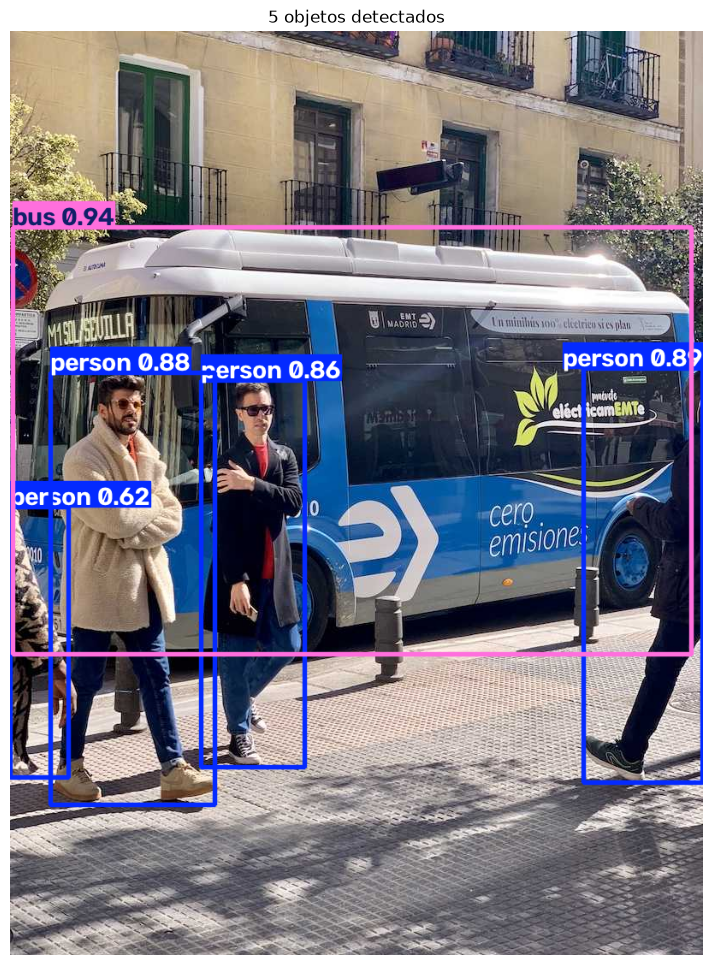

xyxy  (x1,y1,x2,y2) → [3.7987289428710938, 229.38475036621094, 796.231689453125, 728.3489379882812]
xywh  (cx,cy,w,h)   → [400.01519775390625, 478.8668518066406, 792.4329833984375, 498.96417236328125]
xywhn (normalizado)  → [0.494, 0.443, 0.978, 0.462]
conf → 0.94 | cls → 5 = bus
Tiempos (ms): {'preprocess': 0.8, 'inference': 25.6, 'postprocess': 0.6}


In [5]:
res = model(IMG_BUS, conf=0.25, iou=0.7, imgsz=640, device=DEVICE, verbose=False)[0]
mostrar(res.plot(), f"{len(res.boxes)} objetos detectados")

b = res.boxes
print("xyxy  (x1,y1,x2,y2) →", b.xyxy[0].tolist())
print("xywh  (cx,cy,w,h)   →", b.xywh[0].tolist())
print("xywhn (normalizado)  →", [round(v, 3) for v in b.xywhn[0].tolist()])
print("conf →", round(float(b.conf[0]), 3), "| cls →", int(b.cls[0]), "=", res.names[int(b.cls[0])])
print("Tiempos (ms):", {k: round(v, 1) for k, v in res.speed.items()})

In [6]:
def cajas_a_df(res):
    b = res.boxes
    if len(b) == 0:
        return pd.DataFrame(columns=["clase", "conf", "x1", "y1", "x2", "y2", "cx", "cy", "w", "h", "area"])
    xyxy, xywh = b.xyxy.cpu().numpy(), b.xywh.cpu().numpy()
    df = pd.DataFrame(xyxy, columns=["x1", "y1", "x2", "y2"])
    df[["cx", "cy", "w", "h"]] = xywh
    df["area"] = df.w * df.h
    df = df.round(1)
    df.insert(0, "conf", b.conf.cpu().numpy().round(3))
    df.insert(0, "clase", [res.names[int(c)] for c in b.cls])
    return df

df_bus = cajas_a_df(res)
df_bus

,clase,conf,x1,y1,x2,y2,cx,cy,w,h,area
0,bus,0.940,3.800000,229.399994,796.200012,728.299988,400.000000,478.899994,792.400024,499.000000,395395.593750
1,person,0.888,671.000000,394.899994,809.799988,878.700012,740.400024,636.799988,138.800003,483.799988,67171.398438
2,person,0.879,47.400002,399.600006,239.399994,904.200012,143.399994,651.900024,192.000000,504.600006,96882.398438
3,person,0.856,223.100006,408.700012,344.500000,860.400024,283.799988,634.599976,121.400002,451.700012,54838.199219
4,person,0.623,0.000000,556.099976,68.800003,872.299988,34.400002,714.200012,68.699997,316.200012,21738.900391


## A2. ¿Cuántos objetos hay? Conteo por clase

bus.jpg     total= 5 → {'bus': 1, 'person': 4}
zidane.jpg  total= 3 → {'person': 2, 'tie': 1}


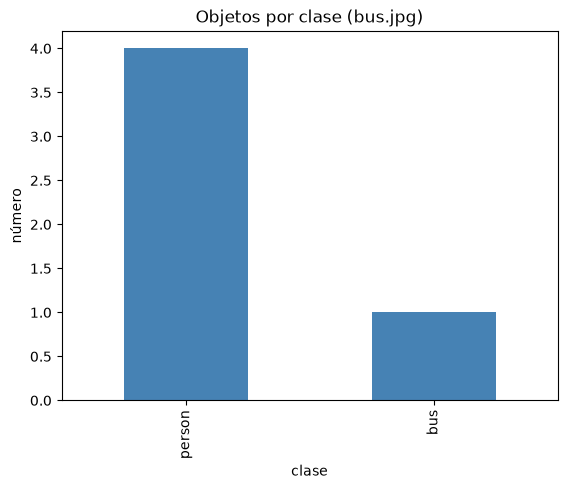

In [7]:
def contar(res):
    return Counter(res.names[int(c)] for c in res.boxes.cls)

for nombre, img in [("bus.jpg", IMG_BUS), ("zidane.jpg", IMG_ZIDANE)]:
    r = model(img, device=DEVICE, verbose=False)[0]
    print(f"{nombre:11s} total={len(r.boxes):2d} →", dict(contar(r)))

conteo = df_bus.clase.value_counts()
conteo.plot.bar(color="steelblue", title="Objetos por clase (bus.jpg)"); plt.ylabel("número"); plt.show()

## A3. ¿De qué color es cada objeto?

YOLO no sabe de colores: **eso lo calculamos nosotros** con la caja. Idea: recortar la caja, quedarnos con la zona central (para no medir el fondo), pasar a HSV y tomar el *tono* (H) dominante de los píxeles con suficiente saturación. Si casi no hay saturación, el objeto es blanco, gris o negro según su brillo (V).

In [8]:
# Rangos de tono en OpenCV (H va de 0 a 179)
RANGOS_H = [(0, 8, "rojo"), (8, 22, "naranja"), (22, 34, "amarillo"), (34, 85, "verde"),
            (85, 100, "cian"), (100, 130, "azul"), (130, 160, "morado"), (160, 180, "rojo")]
BGR_COLOR = {"rojo": (40, 40, 220), "naranja": (0, 140, 255), "amarillo": (0, 220, 240), "verde": (60, 180, 60),
             "cian": (220, 200, 0), "azul": (220, 80, 30), "morado": (160, 50, 140),
             "blanco": (245, 245, 245), "gris": (140, 140, 140), "negro": (20, 20, 20)}

def color_dominante(img_bgr, caja, recorte_central=0.5, sat_min=60, val_min=50):
    x1, y1, x2, y2 = map(int, caja)
    w, h = x2 - x1, y2 - y1
    m = (1 - recorte_central) / 2                     # margen a quitar por lado
    roi = img_bgr[int(y1 + m * h):int(y2 - m * h), int(x1 + m * w):int(x2 - m * w)]
    if roi.size == 0:
        return "desconocido", 0.0
    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV).reshape(-1, 3)
    cromaticos = hsv[(hsv[:, 1] >= sat_min) & (hsv[:, 2] >= val_min)]
    if len(cromaticos) < 0.15 * len(hsv):            # casi sin color → acromático
        v = np.median(hsv[:, 2])
        return ("negro" if v < 60 else "gris" if v < 170 else "blanco"), 1 - len(cromaticos) / len(hsv)
    hist = np.bincount(cromaticos[:, 0], minlength=180)
    h_dom = int(np.argmax(np.convolve(hist, np.ones(5), "same")))  # pico suavizado
    nombre = next(n for a, b_, n in RANGOS_H if a <= h_dom < b_)
    return nombre, len(cromaticos) / len(hsv)

def agregar_colores(df, img_bgr, **kw):
    df = df.copy()
    res_col = [color_dominante(img_bgr, r[["x1", "y1", "x2", "y2"]], **kw) for _, r in df.iterrows()]
    df["color"] = [c for c, _ in res_col]; df["pureza"] = [round(p, 2) for _, p in res_col]
    return df

img_bus = cv2.imread(IMG_BUS)
df_bus = agregar_colores(df_bus, img_bus)
df_bus[["clase", "conf", "color", "pureza", "area"]]

,clase,conf,color,pureza,area
0,bus,0.940,azul,0.60,395395.593750
1,person,0.888,azul,0.35,67171.398438
2,person,0.879,naranja,0.47,96882.398438
3,person,0.856,azul,0.28,54838.199219
4,person,0.623,naranja,0.29,21738.900391


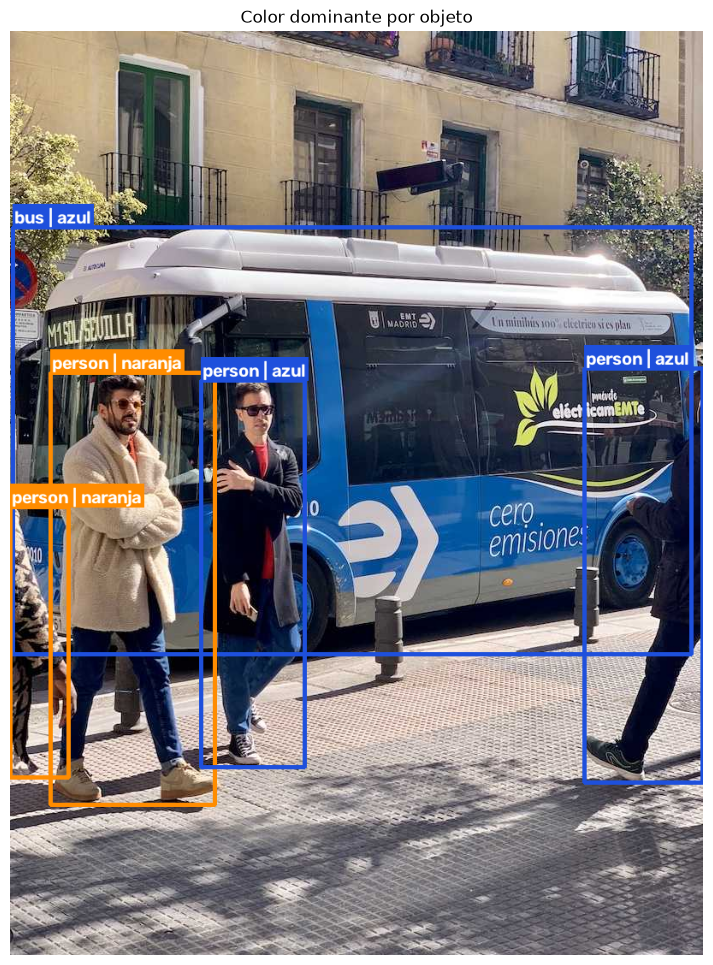

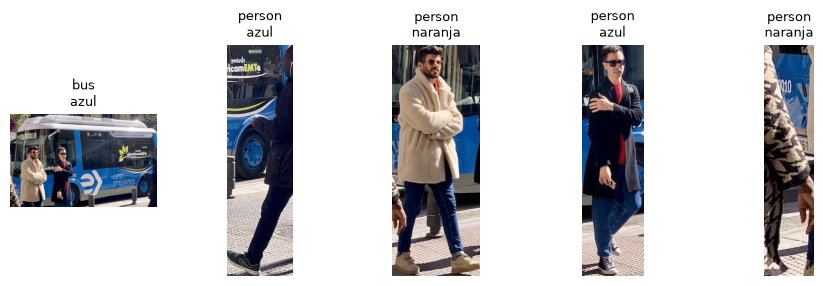

In [9]:
# Dibujamos nuestras PROPIAS cajas: borde del color detectado + etiqueta
def dibujar_colores(img_bgr, df):
    out = img_bgr.copy()
    for _, r in df.iterrows():
        p1, p2 = (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2))
        col = BGR_COLOR.get(r.color, (255, 255, 255))
        cv2.rectangle(out, p1, p2, col, 4)
        txt = f"{r.clase} | {r.color}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
        cv2.rectangle(out, (p1[0], p1[1] - th - 8), (p1[0] + tw + 4, p1[1]), col, -1)
        cv2.putText(out, txt, (p1[0] + 2, p1[1] - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                    (0, 0, 0) if r.color in ("blanco", "amarillo", "cian") else (255, 255, 255), 2)
    return out

mostrar(dibujar_colores(img_bus, df_bus), "Color dominante por objeto")

# Recortes de cada objeto, para verificar a ojo
fig, ax = plt.subplots(1, len(df_bus), figsize=(2.2 * len(df_bus), 3))
for a, (_, r) in zip(np.atleast_1d(ax), df_bus.iterrows()):
    crop = img_bus[int(r.y1):int(r.y2), int(r.x1):int(r.x2)]
    a.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); a.set_title(f"{r.clase}\n{r.color}", fontsize=9); a.axis("off")
plt.show()

In [10]:
# 🔧 AJUSTA A3: barrido de recorte_central × sat_min (color asignado a cada objeto)
filas = []
for rc in [0.3, 0.5, 0.8]:
    for sm in [30, 60, 100]:
        d = agregar_colores(df_bus, img_bus, recorte_central=rc, sat_min=sm)
        filas.append({"recorte": rc, "sat_min": sm,
                      **{f"{i}:{c}": col for i, (c, col) in enumerate(zip(d.clase, d.color))}})
pd.DataFrame(filas)

,recorte,sat_min,0:bus,1:person,2:person,3:person,4:person
0,0.3,30,azul,azul,naranja,naranja,naranja
1,0.3,60,azul,azul,naranja,negro,naranja
2,0.3,100,azul,azul,gris,negro,gris
3,0.5,30,azul,azul,naranja,azul,naranja
4,0.5,60,azul,azul,naranja,azul,naranja
5,0.5,100,azul,azul,gris,azul,gris
6,0.8,30,azul,azul,naranja,azul,naranja
7,0.8,60,azul,azul,naranja,azul,azul
8,0.8,100,azul,azul,gris,azul,azul


In [11]:
# MEJORA (extra A3): K-means con k=3 sobre los píxeles de la zona central; gana el cluster más grande
def nombre_hsv(h, s, v, sat_min=60, val_min=50):
    if s < sat_min or v < val_min:
        return "negro" if v < 60 else "gris" if v < 170 else "blanco"
    return next(n for a, b_, n in RANGOS_H if a <= h < b_)

def color_kmeans(img_bgr, caja, recorte_central=0.5, k=3):
    x1, y1, x2, y2 = map(int, caja)
    w, h = x2 - x1, y2 - y1
    m = (1 - recorte_central) / 2
    roi = img_bgr[int(y1 + m * h):int(y2 - m * h), int(x1 + m * w):int(x2 - m * w)]
    px = roi.reshape(-1, 3).astype(np.float32)
    cv2.setRNGSeed(0)
    _, lab, cen = cv2.kmeans(px, k, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0),
                             3, cv2.KMEANS_PP_CENTERS)
    tam = np.bincount(lab.ravel(), minlength=k)
    nombres = [nombre_hsv(*map(int, cv2.cvtColor(c.astype(np.uint8).reshape(1, 1, 3), cv2.COLOR_BGR2HSV)[0, 0]))
               for c in cen]
    return nombres[int(np.argmax(tam))], {n: round(t / tam.sum(), 2) for n, t in zip(nombres, tam)}

filas = []
for _, r in df_bus.iterrows():
    caja = (r.x1, r.y1, r.x2, r.y2)
    km, grupos = color_kmeans(img_bus, caja)
    filas.append(dict(clase=r.clase, hsv_pico=r.color, kmeans_k3=km, clusters=grupos))
pd.DataFrame(filas)

,clase,hsv_pico,kmeans_k3,clusters
0,bus,azul,azul,"{'azul': 0.25, 'blanco': 0.1}"
1,person,azul,negro,"{'negro': 0.56, 'blanco': 0.26, 'azul': 0.18}"
2,person,naranja,naranja,"{'naranja': 0.49, 'negro': 0.31, 'blanco': 0.2}"
3,person,azul,negro,"{'naranja': 0.09, 'negro': 0.8, 'rojo': 0.11}"
4,person,naranja,gris,"{'negro': 0.41, 'gris': 0.42, 'blanco': 0.17}"


**✍️ RESPONDE A3**
1. ¿En qué objetos acertó el color y en cuáles falló? Explica *por qué* falló (fondo dentro de la caja, ropa de varios colores, iluminación, sombras…).
2. **🔧 AJUSTA** `recorte_central` (0.3, 0.5, 0.8) y `sat_min` (30, 60, 100). ¿Qué combinación funcionó mejor y por qué?
3. Propón una mejora (p. ej. K-means con 3 grupos dentro de la caja, o usar la máscara de `yolo11n-seg`). No es obligatorio implementarla, pero suma.

### 💬 Respuesta A3
*(Evidencia: tabla de barrido y comparación con K-means, arriba; recortes en la figura de A3.)*

1. **Aciertos y fallos** (color a ojo en los recortes de `bus.jpg`):
   - ✅ **bus → azul**: acierta; el autobús es azul y ocupa casi toda la caja.
   - ⚠️ **persona 2 (abrigo beige) → naranja**: "casi": el abrigo es crema/beige, es decir un naranja *muy poco saturado*; con `sat_min=100` pasa a `gris`, que tampoco es exacto. Falla la discretización: no existe la categoría "beige".
   - ❌ **persona 3 (abrigo negro, jeans) → azul** con los parámetros base: dentro de la caja hay mucho **fondo** (el autobús azul) y los **jeans**; el abrigo negro es acromático y queda fuera de los píxeles "cromáticos", así que el pico de tono lo ponen el fondo y el pantalón.
   - ❌ **persona 1 (casi tapada, ropa oscura) → azul**: la caja es muy delgada y contiene sobre todo el autobús del fondo (oclusión).
   - ⚠️ **persona 4 (cortada en el borde, ropa estampada) → naranja**: varios colores a la vez; no hay un único "color dominante" correcto.
   - Causas: fondo dentro de la caja (las cajas son rectángulos, la persona no), ropa con varios colores (abrigo + pantalón), oclusión/recorte por el borde de la imagen y la iluminación de sol/sombra, que cambia la saturación y el valor.
2. **Barrido `recorte_central` × `sat_min`**: la mejor combinación fue **`recorte_central=0.3`, `sat_min=60`**. Con 0.3 sólo se mide el torso (centro de la caja), se descarta el fondo y el abrigo negro de la persona 3 pasa correctamente a `negro`; con 0.8 entra mucho fondo y la persona 4 cambia a `azul` (color del autobús). `sat_min=30` es demasiado permisivo (acepta ruido/sombras como "color") y `sat_min=100` exige tanta saturación que la ropa pálida (el beige) se manda a `gris`. El valor intermedio 60 equilibra ambos errores.
3. **Mejora implementada (extra): K-means con k=3** dentro de la zona central, eligiendo el cluster más grande. Resultado: la persona 3 pasa a `negro` (80 % del recorte) y la persona 1 a `negro` (56 %), ambas más cercanas a la realidad que el pico de tono; el beige de la persona 2 sigue como `naranja` (49 %). Limitación: K-means sigue agrupando por color, no por objeto; lo ideal sería usar la **máscara de `yolo11n-seg`** para medir sólo los píxeles de la persona y descartar el fondo.

## A4. Gráficas de los objetos detectados

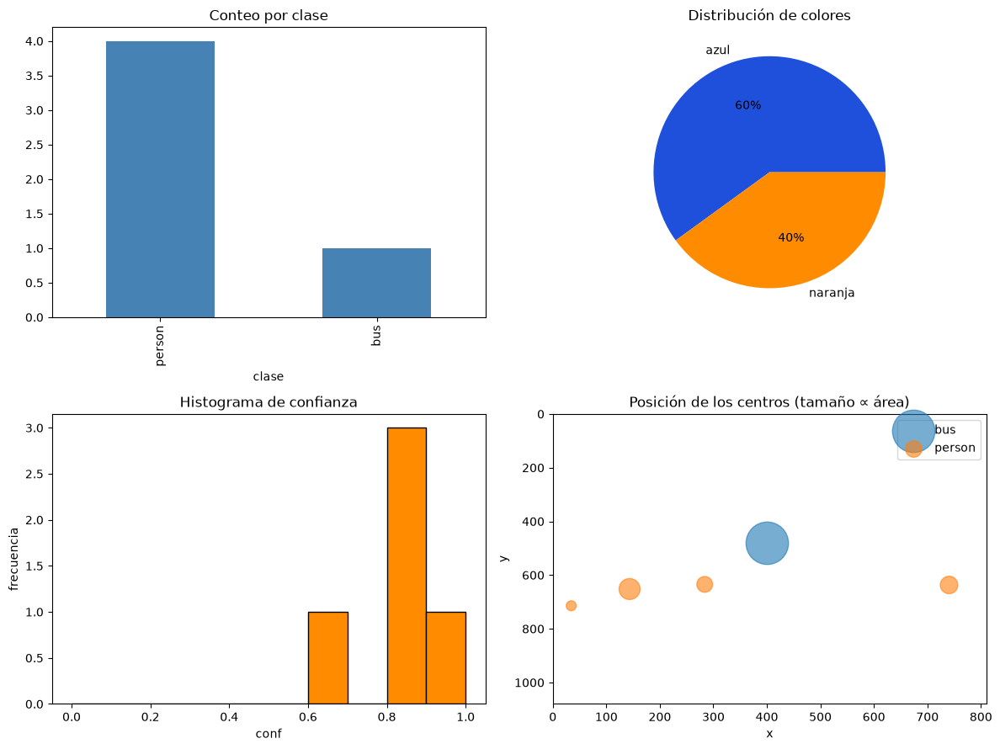

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
df_bus.clase.value_counts().plot.bar(ax=ax[0, 0], color="steelblue", title="Conteo por clase")
df_bus.color.value_counts().plot.pie(ax=ax[0, 1], autopct="%d%%", title="Distribución de colores",
                                     colors=[np.array(BGR_COLOR.get(c, (128,)*3))[::-1] / 255 for c in df_bus.color.value_counts().index])
ax[0, 1].set_ylabel("")
ax[1, 0].hist(df_bus.conf, bins=10, range=(0, 1), color="darkorange", edgecolor="k")
ax[1, 0].set(title="Histograma de confianza", xlabel="conf", ylabel="frecuencia")
H, W = img_bus.shape[:2]
for cl, g in df_bus.groupby("clase"):
    ax[1, 1].scatter(g.cx, g.cy, s=g.area / 300, alpha=.6, label=cl)
ax[1, 1].set(xlim=(0, W), ylim=(H, 0), title="Posición de los centros (tamaño ∝ área)", xlabel="x", ylabel="y")
ax[1, 1].legend(); plt.tight_layout(); plt.show()

## A5. IoU y NMS con tus propias manos

En la mesa redonda vimos que **IoU** (*Intersection over Union*) mide cuánto se traslapan dos cajas, y que **NMS** usa el IoU para eliminar cajas duplicadas. Implementa la función y compárala con la de Ultralytics.

In [13]:
def iou(a, b):
    # a, b = [x1, y1, x2, y2]
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (a[2] - a[0]) * (a[3] - a[1]); area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter + 1e-9)

from ultralytics.utils.metrics import box_iou
cajas = res.boxes.xyxy.cpu()
mi_matriz = np.array([[iou(a.tolist(), b.tolist()) for b in cajas] for a in cajas])
print("¿Coincide con Ultralytics?", np.allclose(mi_matriz, box_iou(cajas, cajas).numpy(), atol=1e-4))
pd.DataFrame(mi_matriz.round(2), index=df_bus.clase, columns=df_bus.clase)

¿Coincide con Ultralytics? True


clase,bus,person,person,person,person
clase,,,,,
bus,1.00,0.1,0.15,0.09,0.03
person,0.10,1.0,0.00,0.00,0.00
person,0.15,0.0,1.00,0.05,0.06
person,0.09,0.0,0.05,1.00,0.00
person,0.03,0.0,0.06,0.00,1.00


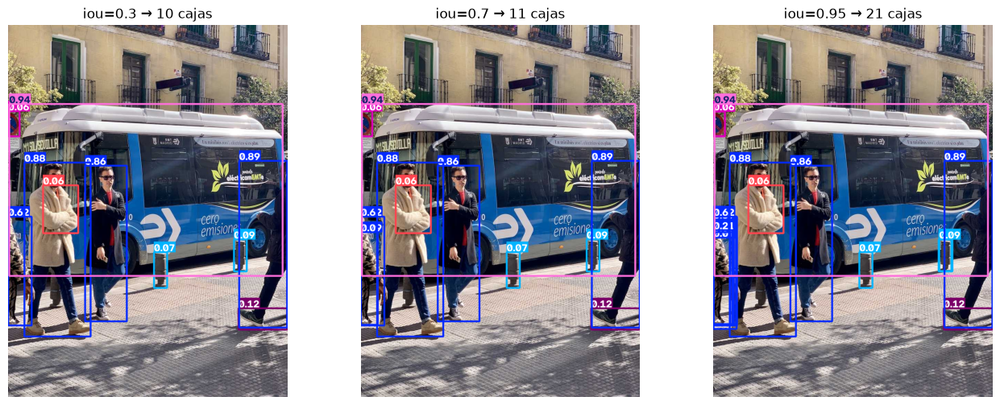

In [14]:
# 🔧 AJUSTA: efecto del umbral IoU de NMS (conf muy bajo para provocar duplicados)
fig, ax = plt.subplots(1, 3, figsize=(16, 6))
for a, u in zip(ax, [0.3, 0.7, 0.95]):
    r = model(IMG_BUS, conf=0.05, iou=u, device=DEVICE, verbose=False)[0]
    a.imshow(cv2.cvtColor(r.plot(labels=False), cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"iou={u} → {len(r.boxes)} cajas")
plt.show()

In [15]:
# 🔧 AJUSTA A5: iou bajo en multitud real (frame 30 del video de la calle, ~20 personas) y agnostic_nms
cap = cv2.VideoCapture(VIDEO_CALLE); cap.set(cv2.CAP_PROP_POS_FRAMES, 30); _, frame_calle = cap.read(); cap.release()
filas = []
for nombre, img in [("bus.jpg", IMG_BUS), ("calle (multitud)", frame_calle)]:
    for u, ag in [(0.3, False), (0.7, False), (0.95, False), (0.7, True), (0.95, True)]:
        r = model(img, conf=0.05, iou=u, agnostic_nms=ag, device=DEVICE, verbose=False)[0]
        filas.append(dict(imagen=nombre, iou=u, agnostic_nms=ag, cajas=len(r.boxes),
                          personas=int((r.boxes.cls == 0).sum()), clases=dict(contar(r))))
pd.DataFrame(filas)

,imagen,iou,agnostic_nms,cajas,personas,clases
0,bus.jpg,0.30,False,10,4,"{'bus': 1, 'person': 4, 'skateboard': 1, 'fire..."
1,bus.jpg,0.70,False,11,5,"{'bus': 1, 'person': 5, 'skateboard': 1, 'fire..."
2,bus.jpg,0.95,False,21,12,"{'bus': 1, 'person': 12, 'skateboard': 1, 'fir..."
3,bus.jpg,0.70,True,11,5,"{'bus': 1, 'person': 5, 'skateboard': 1, 'fire..."
4,bus.jpg,0.95,True,21,12,"{'bus': 1, 'person': 12, 'skateboard': 1, 'fir..."
5,calle (multitud),0.30,False,33,33,{'person': 33}
6,calle (multitud),0.70,False,38,38,{'person': 38}
7,calle (multitud),0.95,False,122,122,{'person': 122}
8,calle (multitud),0.70,True,38,38,{'person': 38}
9,calle (multitud),0.95,True,122,122,{'person': 122}


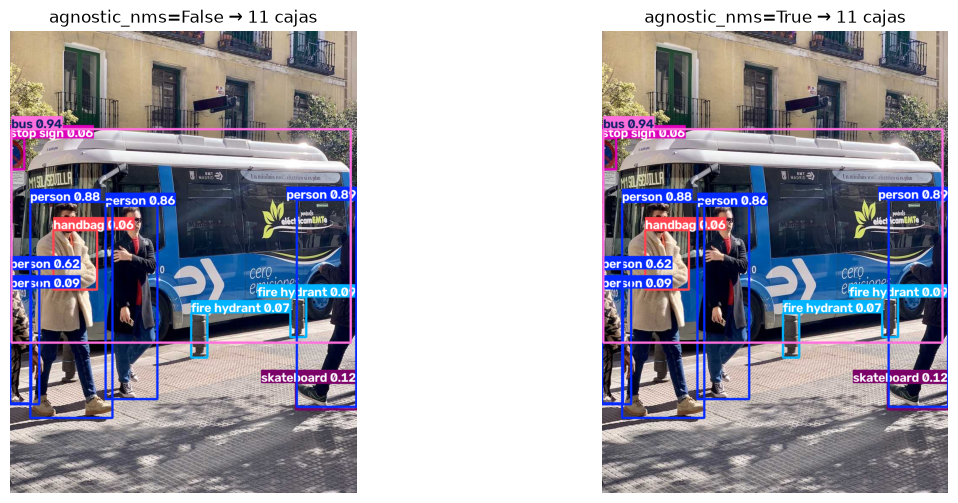

In [16]:
# agnostic_nms: ¿qué cambia en bus.jpg con conf muy bajo? (cajas de clases distintas sobre el mismo objeto)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, ag in zip(ax, [False, True]):
    r = model(IMG_BUS, conf=0.05, iou=0.7, agnostic_nms=ag, device=DEVICE, verbose=False)[0]
    a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"agnostic_nms={ag} → {len(r.boxes)} cajas")
plt.show()

**✍️ RESPONDE A5**
1. ¿Por qué con `iou=0.95` aparecen más cajas? Explícalo con el algoritmo de NMS.
2. ¿Qué pasaría con `iou=0.3` en una foto de una multitud muy apretada?
3. Prueba `agnostic_nms=True`. ¿Qué cambia y en qué caso real te conviene?

### 💬 Respuesta A5
*(Evidencia: tabla "iou × agnostic_nms" y figura bajo A5; se usó `conf=0.05` para provocar duplicados.)*

1. **¿Por qué `iou=0.95` produce más cajas?** NMS ordena las cajas por confianza, se queda con la mejor y **elimina las que se traslapan con ella más de `iou`**. Con `iou=0.95` sólo se elimina una caja si es *prácticamente idéntica* (IoU > 0.95) a otra mejor; los duplicados, desplazados unos píxeles, tienen IoU de 0.6–0.9 y sobreviven. Medido: `bus.jpg` pasa de 11 cajas (`iou=0.7`) a **21**; en el frame de la calle pasa de 38 a **122**.
2. **`iou=0.3` en una multitud apretada:** es demasiado agresivo: dos personas distintas pero pegadas se traslapan más de 0.3 y NMS borra a la de menor confianza → **subconteo**. Medido en el frame de la calle: 38 cajas con `iou=0.7` y 33 con `iou=0.3` (5 personas perdidas por NMS). En `bus.jpg` baja de 11 a 10.
3. **`agnostic_nms=True`:** NMS compara cajas **sin importar la clase** (por defecto sólo compara dentro de la misma clase). En este experimento el número de cajas **no cambió** (11 → 11 con `iou=0.7`; 21 → 21 con `iou=0.95`), porque en `bus.jpg` no hay cajas de clases distintas con IoU suficientemente alto sobre el mismo objeto. Conviene cuando el modelo confunde clases parecidas y se quiere **una sola etiqueta por objeto** (coche/camión/autobús, perro/gato): evita que el mismo objeto salga con dos etiquetas. El riesgo es el contrario: objetos distintos muy traslapados (una persona sobre una bicicleta) pueden fusionarse y perderse uno.

## A6. Barrido de parámetros de inferencia

Los parámetros que **todos** los P deberán justificar en la Parte C:

| Parámetro | Qué controla | Efecto típico al subirlo |
|---|---|---|
| `conf` | Umbral mínimo de confianza | Menos falsos positivos, más objetos perdidos |
| `iou` | Umbral de NMS | Más cajas duplicadas sobreviven |
| `imgsz` | Resolución de entrada | Detecta objetos más pequeños, pero es más lento |
| `max_det` | Máximo de detecciones por imagen | Útil en escenas muy pobladas |
| `classes` | Filtra clases (p. ej. `[0]` = solo personas) | Menos ruido y menos cómputo en post-proceso |

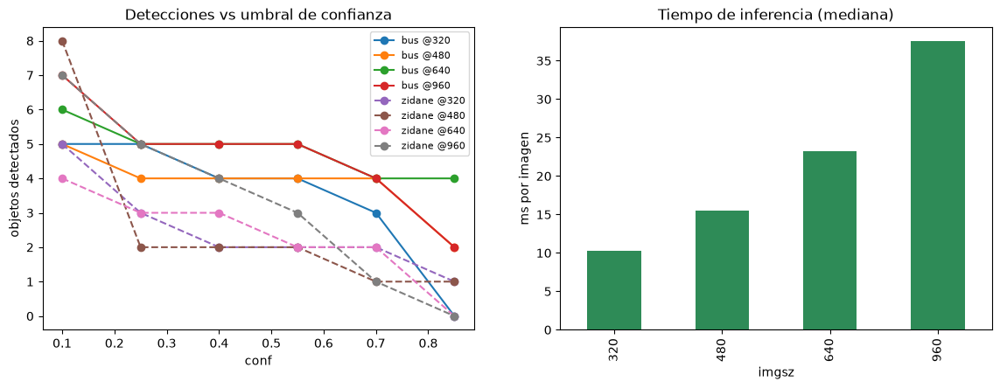

img    bus                zidane               
imgsz  320  480  640  960    320  480  640  960
conf                                           
0.10   5.0  5.0  6.0  7.0    5.0  8.0  4.0  7.0
0.25   5.0  4.0  5.0  5.0    3.0  2.0  3.0  5.0
0.40   4.0  4.0  5.0  5.0    2.0  2.0  3.0  4.0
0.55   4.0  4.0  5.0  5.0    2.0  2.0  2.0  3.0
0.70   3.0  4.0  4.0  4.0    2.0  1.0  2.0  1.0
0.85   0.0  2.0  4.0  2.0    1.0  1.0  0.0  0.0

In [17]:
filas = []
for imgsz in [320, 480, 640, 960]:
    for conf in [0.1, 0.25, 0.4, 0.55, 0.7, 0.85]:
        for img_n, img in [("bus", IMG_BUS), ("zidane", IMG_ZIDANE)]:
            r = model(img, conf=conf, imgsz=imgsz, device=DEVICE, verbose=False)[0]
            filas.append(dict(img=img_n, imgsz=imgsz, conf=conf, n=len(r.boxes),
                              personas=int((r.boxes.cls == 0).sum()), ms=r.speed["inference"]))
barrido = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for (img_n, imgsz), g in barrido.groupby(["img", "imgsz"]):
    ax[0].plot(g.conf, g.n, marker="o", ls="-" if img_n == "bus" else "--", label=f"{img_n} @{imgsz}")
ax[0].set(xlabel="conf", ylabel="objetos detectados", title="Detecciones vs umbral de confianza"); ax[0].legend(fontsize=8)
barrido.groupby("imgsz").ms.median().plot.bar(ax=ax[1], color="seagreen", title="Tiempo de inferencia (mediana)")
ax[1].set_ylabel("ms por imagen"); plt.show()
barrido.pivot_table(index="conf", columns=["img", "imgsz"], values="n")

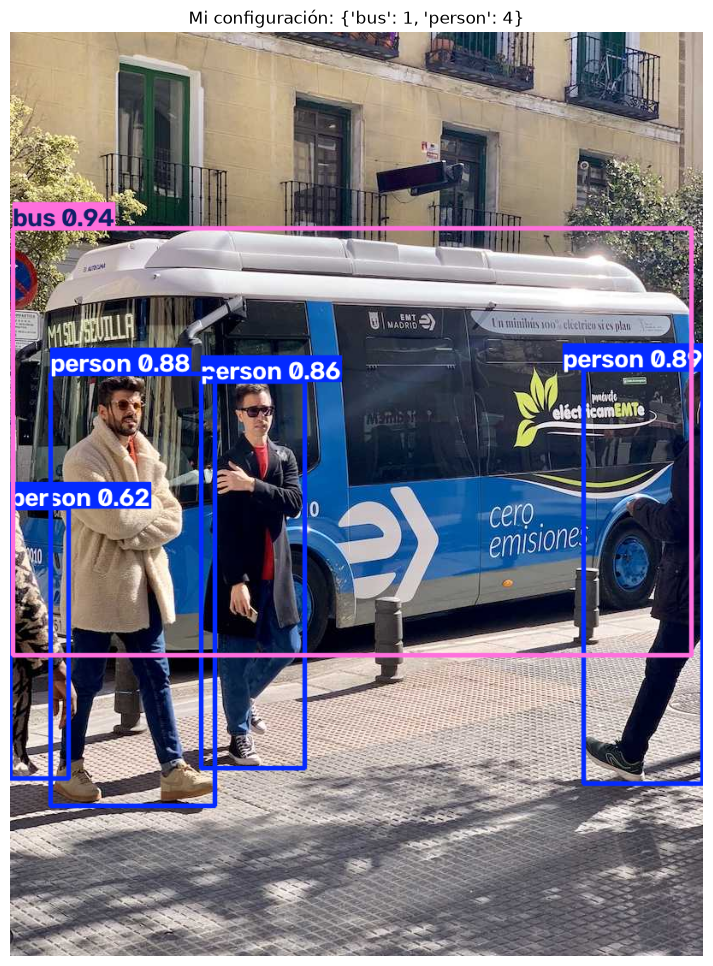

In [18]:
# 🔧 AJUSTA: elige TU configuración y justifícala
MI_CONF, MI_IOU, MI_IMGSZ, MIS_CLASES = 0.4, 0.6, 640, None   # ej. MIS_CLASES=[0, 5] (persona, autobús)
r = model(IMG_BUS, conf=MI_CONF, iou=MI_IOU, imgsz=MI_IMGSZ, classes=MIS_CLASES, max_det=50, device=DEVICE, verbose=False)[0]
mostrar(r.plot(), f"Mi configuración: {dict(contar(r))}")

In [19]:
# Costo de resolución (A6): mediana de inferencia por imgsz
t = barrido.groupby("imgsz").ms.median()
print({k: round(v, 1) for k, v in t.items()}, "→ imgsz=960 es ×", round(t[960] / t[320], 1), "más lento que 320")
# Detecciones de personas en zidane.jpg vs conf (todas las resoluciones)
barrido[barrido.img == "zidane"].pivot_table(index="conf", columns="imgsz", values="personas")

{320: 10.3, 480: 15.5, 640: 23.2, 960: 37.5} → imgsz=960 es × 3.6 más lento que 320


imgsz,320,480,640,960
conf,,,,
0.10,5.0,3.0,2.0,2.0
0.25,3.0,2.0,2.0,2.0
0.40,2.0,2.0,2.0,2.0
0.55,2.0,2.0,2.0,2.0
0.70,2.0,1.0,2.0,1.0
0.85,1.0,1.0,0.0,0.0


## A7. Métricas de detección: Precision, Recall, mAP50 y mAP50-95

Ahora medimos contra **etiquetas reales** (ground truth) usando `coco8` (8 imágenes, descarga < 1 MB). Recuerda:
- **mAP50**: una predicción cuenta como correcta si su IoU con la caja real es ≥ 0.5.
- **mAP50-95**: promedio de mAP con umbrales de IoU de 0.50 a 0.95 — exige cajas mucho más precisas.

In [20]:
met = []
for imgsz in [320, 640]:
    for conf in [0.001, 0.25]:
        v = model.val(data="coco8.yaml", imgsz=imgsz, conf=conf, device=DEVICE, plots=False, verbose=False)
        met.append(dict(imgsz=imgsz, conf=conf, P=v.box.mp, R=v.box.mr, mAP50=v.box.map50, mAP50_95=v.box.map))
df_met = pd.DataFrame(met).round(3); df_met

,imgsz,conf,P,R,mAP50,mAP50_95
0,320,0.001,0.645,0.567,0.682,0.405
1,320,0.250,0.350,0.300,0.285,0.230
2,640,0.001,0.570,0.850,0.854,0.631
3,640,0.250,0.694,0.650,0.643,0.470


In [21]:
# Métricas por clase (última validación)
pd.DataFrame({"clase": [v.names[i] for i in v.box.ap_class_index],
              "AP50": v.box.ap50.round(3), "AP50-95": v.box.ap.round(3)})

,clase,AP50,AP50-95
0,person,0.375,0.208
1,dog,0.995,0.696
2,horse,0.995,0.671
3,elephant,0.495,0.248
4,umbrella,0.995,0.995
5,potted plant,0.000,0.000


### Ajuste fino de N épocas
Igual que en el laboratorio anterior: el modelo **ya está entrenado**, solo lo afinamos 3 épocas sobre `coco8` y comparamos.

In [22]:
LOGGER.setLevel(logging.INFO)      # queremos ver la tabla de pérdidas por época
modelo_ft = YOLO("yolo11n.pt")
modelo_ft.train(data="coco8.yaml", epochs=3, imgsz=320, batch=8, device=DEVICE,
                plots=False, verbose=False, name="ft_coco8", exist_ok=True)
LOGGER.setLevel(logging.WARNING)
v_ft = modelo_ft.val(data="coco8.yaml", imgsz=320, device=DEVICE, plots=False, verbose=False)
v_or = YOLO("yolo11n.pt").val(data="coco8.yaml", imgsz=320, device=DEVICE, plots=False, verbose=False)
pd.DataFrame({"original": [v_or.box.mp, v_or.box.mr, v_or.box.map50, v_or.box.map],
              "3 épocas": [v_ft.box.mp, v_ft.box.mr, v_ft.box.map50, v_ft.box.map]},
             index=["Precision", "Recall", "mAP50", "mAP50-95"]).round(3)

Ultralytics 8.4.176 🚀 Python-3.11.16 torch-2.14.1 CPU (Apple M3 Max)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ft_coco8, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=False, pose=12.0, pretrained=True, 


                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


...

YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 19.2it/s 0.1s

                   all          4         17      0.653      0.583      0.691      0.401


Speed: 0.2ms preprocess, 11.3ms inference, 0.0ms loss, 0.3ms postprocess per image


,original,3 épocas
Precision,0.645,0.653
Recall,0.567,0.583
mAP50,0.682,0.691
mAP50-95,0.405,0.401


**✍️ RESPONDE A6–A7**
1. Con tu barrido: ¿qué `conf` elegirías para (a) un sistema de **seguridad** que no puede perder personas y (b) un **conteo de inventario** donde un falso positivo cuesta dinero? Argumenta con la curva.
2. ¿Cuánto más lento es `imgsz=960` que `imgsz=320`? ¿Cuándo vale la pena pagar ese costo?
3. ¿Por qué `mAP50-95` siempre es menor que `mAP50`?
4. ¿Por qué `model.val()` usa por defecto `conf=0.001` y no `0.25`? (Pista: la curva Precision-Recall necesita *todas* las predicciones.)
5. ¿Las 3 épocas mejoraron o empeoraron el mAP? Con solo 4 imágenes de validación, ¿qué tan confiable es esa conclusión?

### 💬 Respuesta A6–A7
1. **Elección de `conf`** (curvas del barrido; `bus.jpg` a 640 px: 6 objetos con conf=0.1, 5 con 0.25–0.55, 4 con 0.7 y 4 con 0.85; a 320 px con conf=0.85 se pierden *todos*):
   - **(a) Seguridad:** `conf≈0.10–0.25`. Un falso negativo (persona no detectada) es el error caro; se acepta algún falso positivo que un operador o un segundo filtro descarta. Con 0.85 el sistema pierde todo a 320 px y la mitad a 960 px.
   - **(b) Inventario:** `conf≈0.55–0.70`. La curva está *plana* entre 0.4 y 0.7 (a 640 px: 5 → 5 → 4 objetos), es decir, lo que sobrevive es detección sólida y se eliminan los objetos de baja confianza (en `bus.jpg`, conf=0.1 añade clases dudosas como `stop sign`, `skateboard`, `fire hydrant`). Pasar de 0.7 hace caer el conteo (0.85) sin ganar precisión.
2. **`imgsz=960` vs `320`:** mediana de inferencia **37.5 ms vs 10.3 ms → ×3.6 más lento** (CPU, M3 Max). Vale la pena cuando los objetos son **pequeños o lejanos** (en el video de la calle las personas miden ~50 px de alto: a 320 px el detector/tracker casi no ve a nadie, ver Parte C); no vale la pena para objetos grandes y cercanos (bus, Zidane), donde 320–480 px da prácticamente el mismo resultado.
3. **¿Por qué mAP50-95 ≤ mAP50?** mAP50 sólo exige IoU ≥ 0.5; mAP50-95 promedia el AP con umbrales 0.50, 0.55, ..., 0.95. Al endurecer el umbral de IoU el AP **no puede subir**, así que el promedio queda por debajo del AP50. (Medido: 0.854 vs 0.631 a 640 px, `conf=0.001`.)
4. **¿Por qué `val()` usa `conf=0.001`?** El AP es el área bajo la curva Precision-Recall, y esa curva se construye variando el umbral de confianza sobre *todas* las predicciones; con `conf=0.25` se recorta la curva y se subestima el AP. Medido a 640 px: `conf=0.001` → R=0.85 y mAP50=0.854; `conf=0.25` → R=0.65 y mAP50=0.643 (la precisión sube de 0.57 a 0.69, pero el mAP baja porque se perdió recall).
5. **¿Mejoraron las 3 épocas?** Prácticamente **no**: mAP50 0.682 → 0.691 (+0.009), mAP50-95 0.405 → 0.401 (−0.004), P 0.645 → 0.653 y R 0.567 → 0.583. Son variaciones de ~±1 %, dentro del ruido; además la tabla de entrenamiento muestra **las mismas métricas en las 3 épocas** (0.691 / 0.401) porque el *warm-up* usa una tasa de aprendizaje diminuta (`lr≈0.0001`) y los pesos casi no cambian. Con sólo **4 imágenes de validación (17 instancias)**, un objeto mal o bien detectado mueve el mAP varios puntos, así que **la conclusión no es confiable**.

---
# PARTE B — Seguimiento y análisis de movimiento en video

En video, detectar no basta: necesitamos saber que la persona del frame 10 **es la misma** del frame 11. Eso lo hace el **tracker**, que asigna un `id` a cada objeto combinando:
- la predicción de movimiento (filtro de Kalman) de dónde *debería* estar la caja, y
- el emparejamiento (por IoU y/o apariencia) con las cajas nuevas que da YOLO.

Ultralytics trae varios: **ByteTrack**, **BoT-SORT**, **OC-SORT**, **TrackTrack** (por defecto en esta versión), FastTrack y Deep OC-SORT.

## B1. Seguimiento y tabla de trayectorias

In [23]:
def seguir(video, tracker="bytetrack.yaml", conf=0.25, iou=0.7, imgsz=640, classes=None, guardar=None):
    # Ejecuta model.track frame por frame y devuelve un DataFrame con cada caja seguida
    filas, escritor, t0 = [], None, time.time()
    gen = model.track(video, stream=True, persist=True, tracker=tracker, conf=conf, iou=iou,
                      imgsz=imgsz, classes=classes, device=DEVICE, verbose=False)
    for f, r in enumerate(gen):
        if guardar:
            frame = r.plot()
            if escritor is None:
                escritor = cv2.VideoWriter(guardar, cv2.VideoWriter_fourcc(*"mp4v"), info_video(video)["fps"],
                                           (frame.shape[1], frame.shape[0]))
            escritor.write(frame)
        if r.boxes.id is None:
            continue
        for tid, c, cf, (cx, cy, w, h), xyxy in zip(r.boxes.id.int().tolist(), r.boxes.cls.int().tolist(),
                                                    r.boxes.conf.tolist(), r.boxes.xywh.tolist(), r.boxes.xyxy.tolist()):
            filas.append(dict(frame=f, id=tid, clase=r.names[c], conf=cf, cx=cx, cy=cy, w=w, h=h,
                              x1=xyxy[0], y1=xyxy[1], x2=xyxy[2], y2=xyxy[3]))
    if escritor: escritor.release()
    df = pd.DataFrame(filas); df.attrs["seg"] = time.time() - t0
    return df

tracks = seguir(VIDEO_CALLE, guardar="tracking_bytetrack.mp4")
print(f"Filas: {len(tracks)} | IDs únicos: {tracks.id.nunique()} | tiempo: {tracks.attrs['seg']:.1f}s")
mostrar_video("tracking_bytetrack.mp4")
tracks.head()

Filas: 1048 | IDs únicos: 26 | tiempo: 2.0s


,frame,id,clase,conf,cx,cy,w,h,x1,y1,x2,y2
0,0,1,person,0.752396,397.905151,338.518616,33.794556,42.868896,381.007874,317.084167,414.802429,359.953064
1,0,2,person,0.731279,234.893524,250.385956,26.873230,68.499512,221.456909,216.136200,248.330139,284.635712
2,0,3,person,0.697919,97.971405,174.393219,22.645081,57.553589,86.648865,145.616425,109.293945,203.170013
3,0,4,person,0.693669,493.055176,265.455475,29.890747,60.616699,478.109802,235.147125,508.000549,295.763824
4,0,5,person,0.693131,28.814064,297.360779,35.612000,63.597290,11.008064,265.562134,46.620064,329.159424


## B2. ¿Cuántos objetos hay *realmente*? Conteo por frame vs. conteo por ID

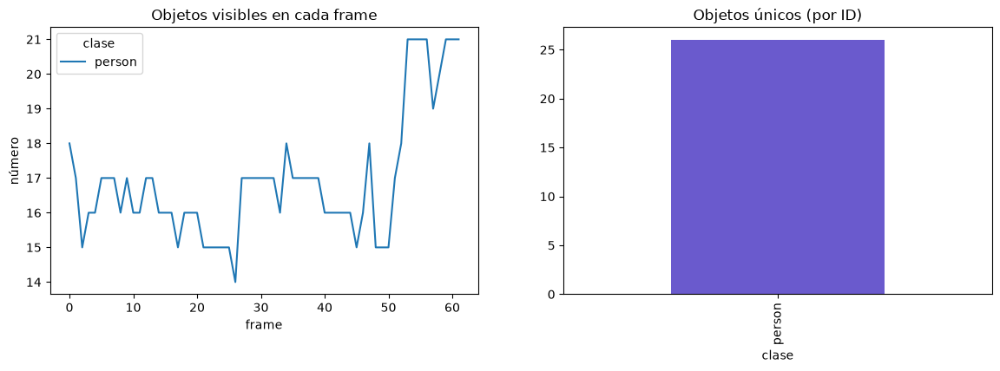

Máximo simultáneo: 21 | Objetos únicos: 26


,clase,frames,conf_media
id,,,
1,person,62,0.79
2,person,62,0.70
3,person,62,0.66
4,person,62,0.71
5,person,54,0.62
6,person,62,0.55
7,person,62,0.60
8,person,62,0.54
9,person,62,0.51


In [24]:
por_frame = tracks.groupby(["frame", "clase"]).size().unstack(fill_value=0)
resumen = tracks.groupby("id").agg(clase=("clase", "first"), frames=("frame", "count"),
                                   conf_media=("conf", "mean")).round(2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
por_frame.plot(ax=ax[0], title="Objetos visibles en cada frame"); ax[0].set_ylabel("número")
resumen.clase.value_counts().plot.bar(ax=ax[1], color="slateblue", title="Objetos únicos (por ID)")
plt.show()
print("Máximo simultáneo:", por_frame.sum(axis=1).max(), "| Objetos únicos:", len(resumen))
resumen

In [25]:
# Color de cada objeto seguido: votación por mayoría a lo largo de los frames
cap, colores_por_id = cv2.VideoCapture(VIDEO_CALLE), defaultdict(list)
for f in range(int(tracks.frame.max()) + 1):
    ok, frame = cap.read()
    if not ok: break
    for _, r in tracks[tracks.frame == f].iterrows():
        colores_por_id[r.id].append(color_dominante(frame, (r.x1, r.y1, r.x2, r.y2))[0])
cap.release()
resumen["color"] = [Counter(colores_por_id[i]).most_common(1)[0][0] for i in resumen.index]
resumen["estabilidad_color"] = [round(Counter(colores_por_id[i]).most_common(1)[0][1] / len(colores_por_id[i]), 2)
                                for i in resumen.index]
resumen

,clase,frames,conf_media,color,estabilidad_color
id,,,,,
1,person,62,0.79,gris,1.00
2,person,62,0.70,gris,1.00
3,person,62,0.66,negro,1.00
4,person,62,0.71,negro,0.74
5,person,54,0.62,gris,0.98
6,person,62,0.55,negro,1.00
7,person,62,0.60,negro,1.00
8,person,62,0.54,gris,1.00
9,person,62,0.51,negro,0.71


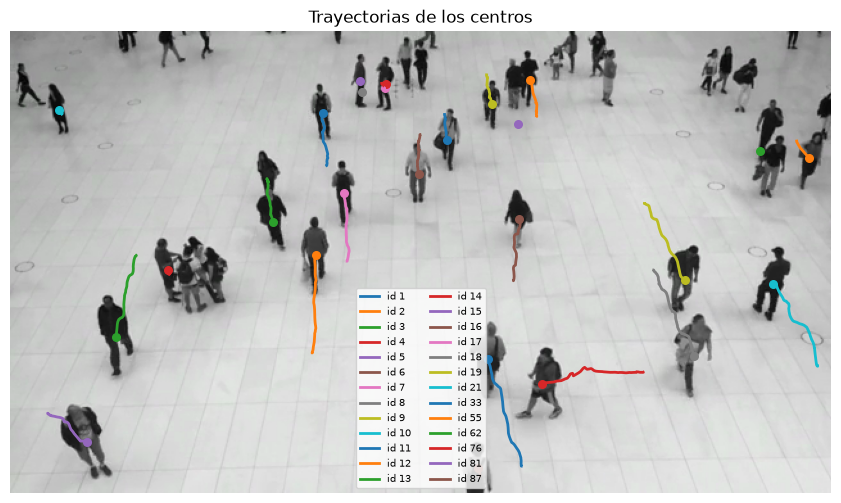

,vel_media,sentido
id,,
1,1.47,←
2,1.26,←
3,1.12,←
4,1.43,←
5,0.79,→
6,0.84,→
7,0.89,←
8,1.29,→
9,1.16,→


In [26]:
# Trayectorias sobre el último frame + velocidad aparente (px/frame)
cap = cv2.VideoCapture(VIDEO_CALLE); cap.set(cv2.CAP_PROP_POS_FRAMES, int(tracks.frame.max())); _, fondo = cap.read(); cap.release()
plt.figure(figsize=(11, 6)); plt.imshow(cv2.cvtColor(fondo, cv2.COLOR_BGR2RGB))
for tid, g in tracks.groupby("id"):
    plt.plot(g.cx, g.cy, lw=2, label=f"id {tid}"); plt.scatter(g.cx.iloc[-1], g.cy.iloc[-1], s=30)
plt.legend(fontsize=7, ncol=2); plt.axis("off"); plt.title("Trayectorias de los centros"); plt.show()

tracks = tracks.sort_values(["id", "frame"])
tracks["vel_px"] = np.hypot(tracks.groupby("id").cx.diff(), tracks.groupby("id").cy.diff())
tracks["dir_x"] = np.sign(tracks.groupby("id").cx.diff())
vel = tracks.groupby("id").agg(vel_media=("vel_px", "mean"), sentido=("dir_x", lambda s: "→" if s.mean() > 0 else "←")).round(2)
vel

## B3. Comparación de trackers

Un buen tracker produce **pocos IDs** (no "inventa" personas nuevas cuando alguien se tapa) y **tracks largos**. Un número de IDs mucho mayor que el número real de personas indica **cambios de identidad (ID switches)**.

⚠️ **Cuidado con la trampa:** *menos IDs no siempre es mejor*. Un tracker con umbrales altos (por ejemplo **TrackTrack**, `track_high_thresh=0.6`, que es el tracker **por defecto** de las Solutions en Ultralytics 8.4) simplemente **ignora** a las personas lejanas con baja confianza. Compara siempre `ids_unicos` contra el *máximo simultáneo* de B2.

In [27]:
comp = []
for trk in ["bytetrack.yaml", "botsort.yaml", "ocsort.yaml", "tracktrack.yaml"]:
    model = YOLO("yolo11n.pt")          # modelo nuevo: el tracker no debe heredar IDs del anterior
    t = seguir(VIDEO_CALLE, tracker=trk)
    largo = t.groupby("id").size()
    comp.append(dict(tracker=trk.replace(".yaml", ""), ids_unicos=t.id.nunique(),
                     largo_medio=round(largo.mean(), 1), tracks_cortos=(largo < 5).sum(), segundos=round(t.attrs["seg"], 1)))
df_trk = pd.DataFrame(comp); df_trk

,tracker,ids_unicos,largo_medio,tracks_cortos,segundos
0,bytetrack,26,40.3,4,1.9
1,botsort,26,40.4,3,1.9
2,ocsort,26,39.9,4,1.8
3,tracktrack,7,47.6,0,2.0


In [28]:
# 🔧 AJUSTA: crea tu propio tracker modificando sus hiperparámetros
import yaml
ruta = os.path.join(os.path.dirname(ultralytics.__file__), "cfg", "trackers", "bytetrack.yaml")
cfg = yaml.safe_load(open(ruta)); print("Original:", cfg)

cfg.update(track_high_thresh=0.5,   # sube → solo detecciones muy seguras abren/actualizan tracks
           new_track_thresh=0.6,    # sube → cuesta más crear un ID nuevo
           track_buffer=60,         # sube → recuerda más tiempo a quien se ocultó (oclusión)
           match_thresh=0.8)        # umbral de emparejamiento
yaml.safe_dump(cfg, open("mi_tracker.yaml", "w"))

model = YOLO("yolo11n.pt")
t = seguir(VIDEO_CALLE, tracker="mi_tracker.yaml", guardar="tracking_mio.mp4")
print("IDs únicos con mi tracker:", t.id.nunique())
mostrar_video("tracking_mio.mp4")

Original: {'tracker_type': 'bytetrack', 'track_high_thresh': 0.25, 'track_low_thresh': 0.1, 'new_track_thresh': 0.25, 'track_buffer': 30, 'match_thresh': 0.8, 'fuse_score': True}


IDs únicos con mi tracker: 12


**✍️ RESPONDE B1–B3**
1. ¿Por qué el *máximo de objetos simultáneos* y el número de *IDs únicos* son distintos? ¿Cuál reportarías a un cliente que pregunta "¿cuántas personas pasaron?"
2. ¿Qué tracker generó menos IDs y tracks más largos? ¿Coincide con lo que ves en el video?
3. TrackTrack generó muchos menos IDs que ByteTrack. ¿Es porque sigue mejor a las personas o porque sigue a *menos* personas? Demuéstralo con `ids_unicos`, el máximo simultáneo y el video.
4. Explica con tus palabras para qué sirve `track_buffer` y qué riesgo tiene subirlo demasiado.
5. ¿El color estimado se mantuvo estable para cada ID? ¿Qué te dice la columna `estabilidad_color`?
6. La velocidad está en **píxeles/frame**. ¿Qué dato extra necesitas para convertirla a km/h?

### 💬 Respuesta B1–B3
1. **Máximo simultáneo (21) vs IDs únicos (26):** el máximo es "cuántos hay a la vez en un frame"; los IDs únicos cuentan a todos los que aparecieron en algún momento (personas que entran/salen del encuadre) **más los IDs "fantasma"** que el tracker crea cuando pierde a alguien y lo vuelve a ver (cambio de identidad). A un cliente que pregunta "¿cuántas personas pasaron?" le reportaría el **número de IDs únicos depurado**: 26 IDs menos los 4 tracks de menos de 5 frames (probables fragmentos, p. ej. IDs 15, 17, 18 con 1–3 frames) ≈ **22 personas**, aclarando que es una estimación entre 21 y 26. El máximo simultáneo sirve para dimensionar aforo, no para "cuántas pasaron".
2. **Trackers:** ByteTrack, BoT-SORT y OC-SORT dieron lo mismo (**26 IDs**, tracks medios de ~40 frames, 3–4 tracks cortos); **TrackTrack generó menos IDs (7), tracks más largos (47.6) y 0 cortos**. Pero eso *no* coincide con el video, donde se ven ~20 personas simultáneas (tabla B2 y montaje del Proyecto 1).
3. **¿TrackTrack sigue mejor o sigue a menos gente?** **Sigue a menos.** Evidencia: (i) 7 IDs únicos < 21 personas simultáneas en B2, no puede estar siguiendo a todos; (ii) su configuración tiene `track_high_thresh=0.6` y `new_track_thresh=0.7`, y los **únicos 7 IDs con `conf_media ≥ 0.60`** en la tabla de B2 son 1, 2, 3, 4, 5, 7 y 21 (exactamente 7); (iii) en el video las personas lejanas (conf 0.3–0.5) no reciben ID con TrackTrack. Menos IDs por *ignorar* gente no es mejor seguimiento.
4. **`track_buffer`:** número de frames que el tracker **mantiene viva** una pista que dejó de detectarse (oclusión, detección fallida) esperando reencontrarla con el mismo ID. Subirlo reduce los cambios de ID tras una oclusión; subirlo demasiado deja **pistas fantasma** que duran mucho y pueden **reasignarse a otra persona** distinta (intercambio de identidad). (Mi tracker con `track_buffer=60` y umbrales más altos dio 12 IDs frente a 26, pero parte de esa reducción es por ignorar detecciones débiles.)
5. **Estabilidad del color:** casi todos los IDs tienen `estabilidad_color` de 1.0 (algunos 0.7–0.9, p. ej. IDs 4, 9, 21). **Cuidado:** el video de la calle está en **escala de grises**, así que el color sólo puede ser `negro/gris/blanco` según el brillo, y una estabilidad alta *no* significa que el color sea correcto, sólo que el brillo del torso no cruza los umbrales V=60/170 de un frame a otro. Los IDs con ~0.7 son los que oscilan alrededor de esos umbrales (sombra/luz).
6. **Para pasar de px/frame a km/h** hacen falta la **escala (metros por píxel)** de la escena y los **fps** (km/h = px/frame × fps × m/px × 3.6), idealmente corrigiendo la **perspectiva** (homografía al plano del suelo), porque los m/px cambian con la distancia a la cámara.

## B4. Flujo óptico: movimiento *sin* detector

El **flujo óptico** (Farnebäck) estima, para cada píxel, un vector de desplazamiento entre dos frames consecutivos. No necesita red neuronal ni clases: solo mide *movimiento*. Es la base de las arquitecturas de dos flujos (*two-stream*) para reconocimiento de acciones.

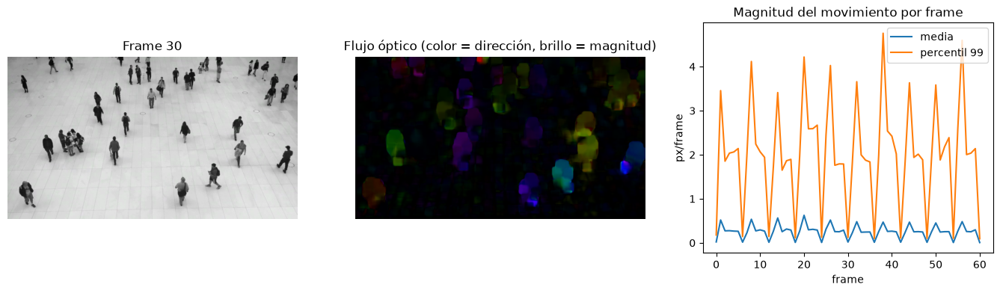

In [29]:
cap = cv2.VideoCapture(VIDEO_CALLE); _, prev = cap.read()
prev_g = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY)
mag_media, mag_max, ejemplo = [], [], None
while True:
    ok, frame = cap.read()
    if not ok: break
    g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    flujo = cv2.calcOpticalFlowFarneback(prev_g, g, None, pyr_scale=0.5, levels=3, winsize=15,
                                         iterations=3, poly_n=5, poly_sigma=1.2, flags=0)
    mag, ang = cv2.cartToPolar(flujo[..., 0], flujo[..., 1])
    mag_media.append(mag.mean()); mag_max.append(np.percentile(mag, 99))
    if len(mag_media) == 30:
        hsv = np.zeros_like(frame); hsv[..., 1] = 255
        hsv[..., 0] = ang * 180 / np.pi / 2; hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
        ejemplo = (frame.copy(), cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR))
    prev_g = g
cap.release()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].imshow(cv2.cvtColor(ejemplo[0], cv2.COLOR_BGR2RGB)); ax[0].set_title("Frame 30"); ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(ejemplo[1], cv2.COLOR_BGR2RGB)); ax[1].set_title("Flujo óptico (color = dirección, brillo = magnitud)"); ax[1].axis("off")
ax[2].plot(mag_media, label="media"); ax[2].plot(mag_max, label="percentil 99")
ax[2].set(title="Magnitud del movimiento por frame", xlabel="frame", ylabel="px/frame"); ax[2].legend()
plt.show()

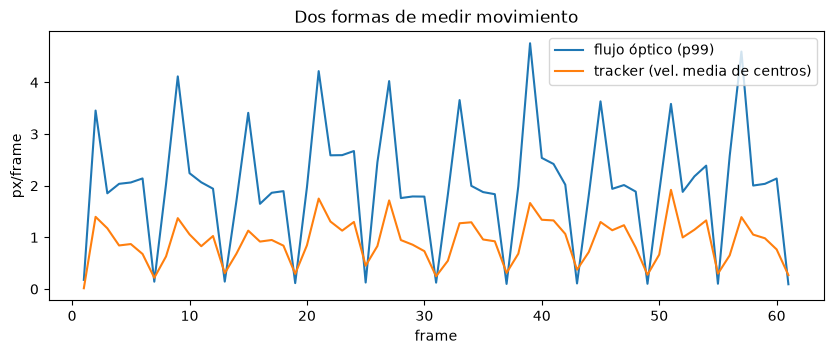

In [30]:
# Flujo óptico vs tracker: ¿coinciden en cuánto movimiento hay?
vel_tracker = tracks.groupby("frame").vel_px.mean().reindex(range(1, len(mag_max) + 1))
plt.figure(figsize=(10, 3.5))
plt.plot(range(1, len(mag_max) + 1), mag_max, label="flujo óptico (p99)")
plt.plot(vel_tracker.index, vel_tracker.values, label="tracker (vel. media de centros)")
plt.xlabel("frame"); plt.ylabel("px/frame"); plt.legend(); plt.title("Dos formas de medir movimiento"); plt.show()

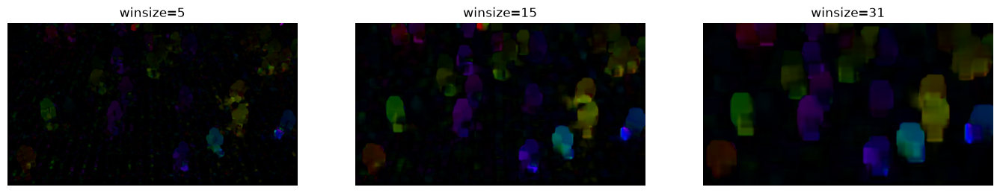

,winsize,mag_media,p99,pct_pix_mov_mayor_0_5,ms
0,5,0.270,1.78,15.5,16.3
1,15,0.287,1.79,17.1,16.3
2,31,0.351,1.77,25.3,16.1


In [31]:
# 🔧 AJUSTA B4: winsize 5, 15, 31 (flujo entre frames 29→30)
cap = cv2.VideoCapture(VIDEO_CALLE); fr = []
for _ in range(31):
    fr.append(cap.read()[1])
cap.release()
g0, g1 = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in fr[29:31]]
fig, ax = plt.subplots(1, 3, figsize=(17, 4)); filas = []
for a, ws in zip(ax, [5, 15, 31]):
    t0 = time.time()
    fl = cv2.calcOpticalFlowFarneback(g0, g1, None, pyr_scale=0.5, levels=3, winsize=ws, iterations=3,
                                      poly_n=5, poly_sigma=1.2, flags=0)
    dt = (time.time() - t0) * 1000
    mag, ang = cv2.cartToPolar(fl[..., 0], fl[..., 1])
    hsv = np.zeros_like(fr[30]); hsv[..., 1] = 255
    hsv[..., 0] = ang * 180 / np.pi / 2; hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    a.imshow(cv2.cvtColor(cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR), cv2.COLOR_BGR2RGB)); a.axis("off"); a.set_title(f"winsize={ws}")
    filas.append(dict(winsize=ws, mag_media=round(float(mag.mean()), 3), p99=round(float(np.percentile(mag, 99)), 2),
                      pct_pix_mov_mayor_0_5=round(float((mag > 0.5).mean() * 100), 1), ms=round(dt, 1)))
plt.show()
pd.DataFrame(filas)

**✍️ RESPONDE B4**
1. En la imagen HSV, ¿qué significa que dos personas tengan colores distintos?
2. **🔧 AJUSTA** `winsize` (5, 15, 31). ¿Qué pasa con el ruido y con el detalle del flujo?
3. Menciona una ventaja del flujo óptico frente al tracker y una ventaja del tracker frente al flujo óptico.
4. **Concepto C3D:** una red 3D convolucional usa filtros de tamaño `3×3×3` (alto × ancho × **tiempo**). Explica qué puede "ver" una C3D que una CNN 2D aplicada frame por frame no puede, y por qué es mucho más costosa. (No la entrenamos: con internet lento, los pesos pesan cientos de MB.)

### 💬 Respuesta B4
1. **Colores en la imagen HSV:** el **tono (H)** codifica la **dirección** del movimiento (el ángulo del vector de flujo) y el **brillo (V)** su **magnitud**. Dos personas con colores distintos se mueven en direcciones distintas (p. ej. verde vs morado/amarillo); mismo color = misma dirección. Fondo negro = sin movimiento.
2. **`winsize` 5 / 15 / 31** (medido entre los frames 29→30):

   | winsize | magnitud media | % de píxeles con mov. > 0.5 px | aspecto |
   |---|---|---|---|
   | 5 | 0.270 | 15.5 % | **muy ruidoso**: puntos sueltos en el fondo, pero con bordes finos y detalle |
   | 15 | 0.287 | 17.1 % | compromiso: siluetas limpias y poco ruido de fondo |
   | 31 | 0.351 | 25.3 % | **muy suave**: bloques grandes con halos, une personas vecinas y "reparte" movimiento al fondo (más píxeles "en movimiento" sin que haya nada) |

   Ventana pequeña = más detalle y más ruido; ventana grande = más robusta al ruido y a movimientos grandes, pero borrosa. El tiempo fue similar (~15 ms) en las tres.
3. **Ventaja del flujo óptico:** no necesita detector ni clases (mide *cualquier* movimiento, incluso de objetos que YOLO no conoce) y da un campo **denso** por píxel (dirección y magnitud, detalle de extremidades). **Ventaja del tracker:** mantiene **identidad** (ID), trayectorias por objeto, clase y conteo; además sigue siendo útil cuando la persona se detiene (el flujo ahí vale 0).
4. **C3D:** un filtro `3×3×3` convoluciona también a lo largo del **tiempo**, así que aprende **patrones espacio-temporales** (dirección y velocidad, cómo cambia la postura, "saludar" vs "estar parado") dentro de un solo filtro. Una CNN 2D por frame sólo ve la apariencia de un frame; no distingue a alguien que camina de alguien de pie sin un módulo posterior (RNN, fusión de frames). Cuesta mucho más: cada filtro tiene ×3 pesos (27 vs 9 por canal de entrada), procesa **T frames a la vez** (entradas 4D: tiempo×alto×ancho) y los FLOPs y la memoria crecen con T; por eso los pesos y el entrenamiento son mucho más pesados.

---
# PARTE C — Ultralytics Solutions (aplicados)


| Parte | Solución | Pregunta de negocio | Video |
|---|---|---|---|
| 1 | `ObjectCounter` | ¿Cuántas personas entran y salen por una línea? | calle |
| 2 | `AIGym` | ¿Cuántas repeticiones hizo y con qué ángulo? | pose |
| 3 | `Heatmap` | ¿Por dónde circula más la gente? | calle |
| 4 | `SpeedEstimator` | ¿A qué velocidad se mueven? | calle |
| 5 | `RegionCounter` + `QueueManager` | ¿Cuánta gente hay en una zona / en la fila? | calle |
| 6 | `TrackZone` + `ObjectBlurrer` | ¿Podemos analizar solo una zona y **anonimizar** personas? | calle |

> Todas las celdas base usan `tracker="bytetrack.yaml"` para que los resultados sean comparables con la Parte B. Si lo quitan, la Solution usa **TrackTrack** (el valor por defecto) y verán muchos menos objetos: el barrido obligatorio compara ambos.

### Obligatorio para TODOS los proyectos
1. Correr la solución con la configuración base y mostrar el video resultante.
2. **🔧 Barrido de parámetros 2.1**: al menos `conf` (3 valores), `imgsz` (2 valores) y `tracker` (2 valores) usando `barrido_solucion`. La columna `fps_proc` indica cuántos frames por segundo procesó su configuración.
3. Graficar la métrica principal de su solución a lo largo del tiempo.
4. Responder sus preguntas específicas **y** las preguntas comunes C-final.

In [32]:
def procesar_video(sol, video, salida=None, max_frames=None, extra=None):
    # Ejecuta una Ultralytics Solution frame por frame. Devuelve (DataFrame de métricas por frame, segundos)
    cap, filas, escritor, t0 = cv2.VideoCapture(video), [], None, time.time()
    fps = cap.get(5) or 30
    f = 0
    nivel = LOGGER.level; LOGGER.setLevel(logging.ERROR)   # evita el aviso "No tracks found" en cada frame
    while cap.isOpened():
        ok, frame = cap.read()
        if not ok or (max_frames and f >= max_frames): break
        r = sol(frame)
        fila = dict(frame=f, t=f / fps, total_tracks=r.total_tracks, in_count=r.in_count, out_count=r.out_count,
                    queue_count=r.queue_count, ms_track=r.speed.get("track", np.nan))
        if extra: fila.update(extra(r))
        filas.append(fila)
        if salida:
            if escritor is None:
                h, w = r.plot_im.shape[:2]
                escritor = cv2.VideoWriter(salida, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
            escritor.write(r.plot_im)
        f += 1
    cap.release(); LOGGER.setLevel(nivel)
    if escritor: escritor.release()
    df = pd.DataFrame(filas)
    sin = int((df.total_tracks == 0).sum()) if len(df) else 0
    if sin: print(f"⚠️ {sin} de {len(df)} frames sin ningún objeto seguido (conf={sol.CFG.get('conf')}, imgsz={sol.CFG.get('imgsz')})")
    return df, time.time() - t0

def barrido_solucion(crear_sol, video, metrica, confs=(0.15, 0.35, 0.6), imgszs=(320, 640),
                     trackers=("bytetrack.yaml", "tracktrack.yaml"), extra=None):
    # crear_sol(conf, imgsz, tracker) debe devolver una solución NUEVA (sin memoria de otra corrida)
    filas = []
    for tr in trackers:
        for sz in imgszs:
            for c in confs:
                df, seg = procesar_video(crear_sol(c, sz, tr), video, extra=extra)
                filas.append(dict(tracker=tr.replace(".yaml", ""), imgsz=sz, conf=c,
                                  resultado=metrica(df), fps_proc=round(len(df) / seg, 1)))
    return pd.DataFrame(filas)

W, H = info_video(VIDEO_CALLE)["ancho"], info_video(VIDEO_CALLE)["alto"]
LINEA = [(20, H // 2), (W - 20, H // 2)]                                          # línea horizontal
ZONA  = [(W // 4, H // 4), (3 * W // 4, H // 4), (3 * W // 4, 3 * H // 4), (W // 4, 3 * H // 4)]  # rectángulo
print("Video", W, "x", H, "| LINEA:", LINEA, "| ZONA:", ZONA)

Video 640 x 360 | LINEA: [(20, 180), (620, 180)] | ZONA: [(160, 90), (480, 90), (480, 270), (160, 270)]


## Proyecto 1 — `ObjectCounter`: contador de entradas y salidas
Cuenta un objeto cuando su trayectoria **cruza** la línea (o entra/sale del polígono). `classwise_count` desglosa por clase.

ENTRADAS=2  SALIDAS=2  (2.0s)


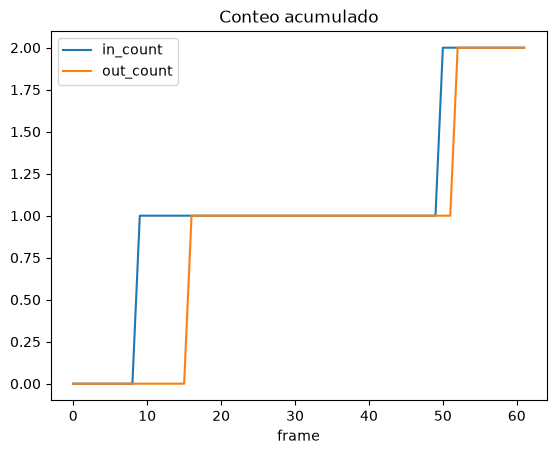

In [33]:
contador = solutions.ObjectCounter(model="yolo11n.pt", region=LINEA, classes=[0],   # 0 = persona
                                   conf=0.25, iou=0.7, imgsz=640, tracker="bytetrack.yaml",
                                   show=False, verbose=False, device=DEVICE)
df1, seg = procesar_video(contador, VIDEO_CALLE, "eq1_contador.mp4",
                          extra=lambda r: {"por_clase": str(r.classwise_count)})
print(f"ENTRADAS={df1.in_count.iloc[-1]}  SALIDAS={df1.out_count.iloc[-1]}  ({seg:.1f}s)")
mostrar_video("eq1_contador.mp4")
df1[["in_count", "out_count"]].plot(title="Conteo acumulado"); plt.xlabel("frame"); plt.show()

In [34]:
# 🔧 Barrido obligatorio
b1 = barrido_solucion(lambda c, sz, tr: solutions.ObjectCounter(model="yolo11n.pt", region=LINEA, classes=[0], conf=c,
                      imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: d.in_count.iloc[-1] + d.out_count.iloc[-1])
b1

⚠️ 60 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.15, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.35, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,3,71.8
1,bytetrack,320,0.35,1,70.8
2,bytetrack,320,0.60,0,75.4
3,bytetrack,640,0.15,4,29.7
4,bytetrack,640,0.35,4,29.0
5,bytetrack,640,0.60,3,32.8
6,tracktrack,320,0.15,0,61.9
7,tracktrack,320,0.35,0,59.9
8,tracktrack,320,0.60,0,68.5
9,tracktrack,640,0.15,2,31.0


In [35]:
# Proyecto 1 (a): línea vertical y polígono vs línea horizontal (todas con bytetrack, conf=0.25)
LINEA_V = [(W // 2, 20), (W // 2, H - 20)]
filas = []
for nombre, reg_, arch in [("línea horizontal", LINEA, None), ("línea vertical", LINEA_V, "eq1_vertical.mp4"),
                           ("polígono ZONA", ZONA, "eq1_poligono.mp4")]:
    c = solutions.ObjectCounter(model="yolo11n.pt", region=reg_, classes=[0], conf=0.25, iou=0.7, imgsz=640,
                                tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
    d, seg = procesar_video(c, VIDEO_CALLE, arch)
    filas.append(dict(region=nombre, entradas=int(d.in_count.iloc[-1]), salidas=int(d.out_count.iloc[-1]),
                      total=int(d.in_count.iloc[-1] + d.out_count.iloc[-1])))
pd.DataFrame(filas)

,region,entradas,salidas,total
0,línea horizontal,2,2,4
1,línea vertical,0,0,0
2,polígono ZONA,5,3,8


In [36]:
# Proyecto 1 (b)(c): verificación independiente con la tabla de trayectorias de B1 (ByteTrack, frames/IDs reales)
tr = tracks.sort_values(["id", "frame"]).copy()
tr["lado"] = np.sign(tr.cy - H // 2)          # arriba (-1) / abajo (+1) de la línea horizontal
def resumen_cruce(g):
    d = g.lado.diff().fillna(0)
    return pd.Series(dict(frames=len(g), cruces=int((d != 0).sum()),
                          sentido=("↓" if (d > 0).sum() > (d < 0).sum() else "↑") if (d != 0).any() else "-"))
cruces = tr.groupby("id")[["frame", "lado"]].apply(resumen_cruce)
print("IDs que cruzan la línea y=H/2:", int((cruces.cruces > 0).sum()), "| ↓:", int((cruces.sentido == "↓").sum()),
      "| ↑:", int((cruces.sentido == "↑").sum()), "| IDs con >1 cruce (vaivén):", int((cruces.cruces > 1).sum()))
print("Cruces de IDs de vida corta (<10 frames), posibles ID-switch:", int(((cruces.cruces > 0) & (cruces.frames < 10)).sum()))
cruces[cruces.cruces > 0]

IDs que cruzan la línea y=H/2: 4 | ↓: 2 | ↑: 2 | IDs con >1 cruce (vaivén): 0
Cruces de IDs de vida corta (<10 frames), posibles ID-switch: 0


,frames,cruces,sentido
id,,,
2,62,1,↑
3,62,1,↓
6,62,1,↑
9,62,1,↓


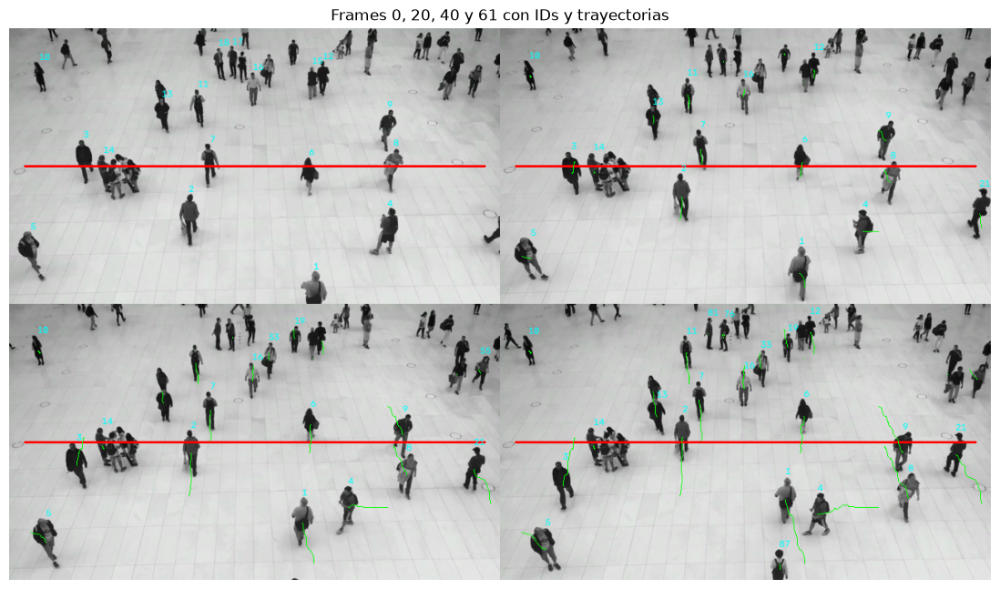

In [37]:
# Evidencia visual: frames 0, 20, 40, 61 con la línea y las trayectorias acumuladas (para contar a mano)
cap = cv2.VideoCapture(VIDEO_CALLE); vistas = []
for f in range(62):
    ok, fr_ = cap.read()
    if f in (0, 20, 40, 61):
        im = fr_.copy()
        cv2.line(im, LINEA[0], LINEA[1], (0, 0, 255), 2)
        for tid, g in tracks[tracks.frame <= f].groupby("id"):
            pts = g[["cx", "cy"]].values.astype(np.int32)
            cv2.polylines(im, [pts], False, (0, 255, 0), 1)
            if g.frame.iloc[-1] == f:
                cv2.putText(im, str(tid), (int(g.cx.iloc[-1]), int(g.y1.iloc[-1]) - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 0), 1)
        vistas.append(im)
cap.release()
mostrar(np.vstack([np.hstack(vistas[:2]), np.hstack(vistas[2:])]), "Frames 0, 20, 40 y 61 con IDs y trayectorias", ancho=14)

**✍️ Proyecto 1:** (a) Cambia la línea a vertical y luego a un polígono (`region=ZONA`). ¿Cuál cuenta mejor en este video y por qué? (b) Cuenta a mano las personas que cruzan. ¿Qué configuración del barrido se acercó más? (c) Si un ID cambia al cruzar la línea, ¿se cuenta doble? Busca evidencia.

### 💬 Respuesta Proyecto 1 — `ObjectCounter`
**(a) Línea vertical y polígono** (bytetrack, `conf=0.25`, `imgsz=640`):

| región | entradas | salidas | total |
|---|---|---|---|
| línea horizontal (base, y=H/2) | 2 | 2 | 4 |
| línea vertical (x=W/2) | 0 | 0 | 0 |
| polígono `ZONA` | 5 | 3 | 8 |

La **horizontal cuenta mejor** en este video: en el montaje de trayectorias la gente camina sobre todo **de arriba a abajo (y viceversa)**, así que una línea horizontal es *perpendicular* al flujo y la cruzan; una línea vertical es *paralela* al flujo y casi nadie la cruza (0). El polígono cuenta algo distinto: entradas/salidas de una *zona* por cualquiera de sus cuatro lados (8 eventos), útil para aforo pero no para "cuántos cruzaron por la línea".

**(b) Conteo "a mano":** con las trayectorias de B1 y el montaje de los frames 0/20/40/61 cruzan la línea **4 personas (IDs 2, 3, 6 y 9: 2↓ y 2↑)**; además hay un grupo de ~4–5 personas pegadas (ID 14) cerca de la línea que el tracker fusiona en una sola caja. *(Nota: es una verificación sobre los tracks, no un conteo totalmente independiente; el video sólo dura 2 s y las personas miden ~50 px.)* La configuración del barrido que más se acerca es **bytetrack @640 px con conf 0.15 o 0.35 → 4**; con `conf=0.6` baja a 3, a 320 px baja a 0–3 y **tracktrack @640 da 2** (ve menos gente).

**(c) ¿Doble conteo si cambia el ID?** `ObjectCounter` guarda los IDs ya contados (`counted_ids`), así que **un mismo ID nunca cuenta dos veces**. El doble conteo ocurre sólo si el tracker le da **un ID nuevo** a la misma persona *después* de que el primero ya cruzó y el nuevo vuelve a cruzar. Evidencia en esta corrida: **0 IDs con más de un cruce** y **0 cruces de IDs de vida corta (<10 frames)**, así que no se encontró doble conteo; el error que sí aparece es el **subconteo** del grupo apretado (ID 14).

## Proyecto 2 — `AIGym`: contador de repeticiones por ángulo
Usa un modelo de **pose** (17 puntos clave COCO). `kpts=[6, 8, 10]` = hombro, codo y muñeca **derechos**: el ángulo en el codo decide si la etapa es `up` o `down`.

Puntos clave: 5/6 hombros · 7/8 codos · 9/10 muñecas · 11/12 caderas · 13/14 rodillas · 15/16 tobillos (impar = izquierdo).

Repeticiones: 1 (el video demo dura solo 2 s; graben uno propio de ≤ 10 s para más repeticiones)


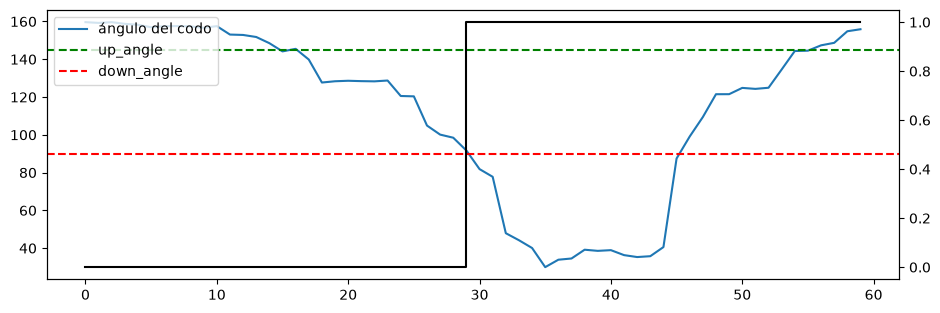

In [38]:
gym = solutions.AIGym(model="yolo11n-pose.pt", kpts=[6, 8, 10], up_angle=145.0, down_angle=90.0,
                      conf=0.25, imgsz=640, tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
ext_gym = lambda r: {"reps": r.workout_count[0] if r.workout_count else 0,
                     "angulo": r.workout_angle[0] if r.workout_angle else np.nan,
                     "etapa": r.workout_stage[0] if r.workout_stage else "-"}
df2, seg = procesar_video(gym, VIDEO_POSE, "eq2_gym.mp4", extra=ext_gym)
print("Repeticiones:", df2.reps.max(), "(el video demo dura solo 2 s; graben uno propio de ≤ 10 s para más repeticiones)")
mostrar_video("eq2_gym.mp4")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(df2.frame, df2.angulo, label="ángulo del codo")
ax.axhline(145, ls="--", c="g", label="up_angle"); ax.axhline(90, ls="--", c="r", label="down_angle")
ax2 = ax.twinx(); ax2.step(df2.frame, df2.reps, c="k", label="reps"); ax.legend(loc="upper left"); plt.show()

In [39]:
# 🔧 Barrido obligatorio (+ prueben distintos up_angle/down_angle y kpts=[5, 7, 9])
b2 = barrido_solucion(lambda c, sz, tr: solutions.AIGym(model="yolo11n-pose.pt", kpts=[6, 8, 10], up_angle=145.0,
                      down_angle=90.0, conf=c, imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_POSE, metrica=lambda d: d.reps.max(), extra=ext_gym)
b2

,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,1,66.4
1,bytetrack,320,0.35,1,66.7
2,bytetrack,320,0.60,1,66.0
3,bytetrack,640,0.15,1,30.4
4,bytetrack,640,0.35,1,31.1
5,bytetrack,640,0.60,1,30.6
6,tracktrack,320,0.15,1,62.8
7,tracktrack,320,0.35,1,63.4
8,tracktrack,320,0.60,1,62.3
9,tracktrack,640,0.15,1,30.2


In [40]:
# Proyecto 2: umbrales alternativos, brazo izquierdo y conf alto
print(f"Ángulo del codo en el video: min={df2.angulo.min():.0f}°  max={df2.angulo.max():.0f}°")
variantes = [("base 145/90 · brazo der. [6,8,10]", [6, 8, 10], 145, 90, 0.25),
             ("160/100 · der.", [6, 8, 10], 160, 100, 0.25),
             ("130/70 · der.", [6, 8, 10], 130, 70, 0.25),
             ("145/90 · izq. [5,7,9]", [5, 7, 9], 145, 90, 0.25),
             ("145/90 · der. conf=0.7", [6, 8, 10], 145, 90, 0.7),
             ("145/90 · der. conf=0.9", [6, 8, 10], 145, 90, 0.9)]
filas = []
for nombre, k, up, dn, c in variantes:
    g = solutions.AIGym(model="yolo11n-pose.pt", kpts=k, up_angle=float(up), down_angle=float(dn), conf=c, imgsz=640,
                        tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
    d, _ = procesar_video(g, VIDEO_POSE, extra=ext_gym)
    filas.append(dict(variante=nombre, reps=int(d.reps.max()), ang_min=round(d.angulo.min(), 0), ang_max=round(d.angulo.max(), 0),
                      frames_sin_persona=int((d.total_tracks == 0).sum())))
pd.DataFrame(filas)

Ángulo del codo en el video: min=30°  max=160°


⚠️ 60 de 60 frames sin ningún objeto seguido (conf=0.9, imgsz=640)


,variante,reps,ang_min,ang_max,frames_sin_persona
0,"base 145/90 · brazo der. [6,8,10]",1,30.0,160.0,0
1,160/100 · der.,0,30.0,160.0,0
2,130/70 · der.,1,30.0,160.0,0
3,"145/90 · izq. [5,7,9]",0,15.0,144.0,0
4,145/90 · der. conf=0.7,1,30.0,160.0,0
5,145/90 · der. conf=0.9,0,NaN,NaN,60


**✍️ Proyecto 2:** (a) Con la gráfica del ángulo, ¿los umbrales 145°/90° están bien elegidos? Propón los tuyos y justifica. (b) ¿Qué pasa si usas el brazo izquierdo `[5, 7, 9]`? (c) ¿Por qué un `conf` alto puede *bajar* el número de repeticiones? (d) ¿Qué puntos clave usarías para contar sentadillas?

### 💬 Respuesta Proyecto 2 — `AIGym`
Ángulo del codo en el video: **mínimo 30°, máximo 160°** (en la gráfica: parte de ~160°, baja a ~30° y vuelve a ~156°).

| variante | reps |
|---|---|
| 145°/90°, brazo der. [6,8,10] (base) | 1 |
| 160°/100° | **0** |
| 130°/70° | 1 |
| 145°/90°, brazo izq. [5,7,9] | **0** (ángulo 15°–144°) |
| 145°/90°, conf=0.7 | 1 |
| 145°/90°, conf=0.9 | **0** (ninguna persona seguida en 60/60 frames) |

**(a)** 145°/90° **están razonablemente bien**: el codo llega a ~156° al extender (>145°) y baja a ~30° al flexionar (<90°). Los umbrales deben quedar **entre los extremos reales** con holgura: el ángulo sólo llega a 160°/156°, por eso 160° no se supera y se obtienen 0 reps. Propongo **`up_angle=140°`, `down_angle=80°`**: ~15° de margen respecto del extremo superior (156°), mucha holgura respecto de 30°, y una histéresis de 60° que evita contar el temblor del ángulo como repeticiones. En el barrido el conteo no cambió con conf/imgsz/tracker (siempre 1 repetición): la pose de una persona grande y cercana es robusta.
**(b) Brazo izquierdo [5,7,9]:** da **0 repeticiones** con los mismos umbrales; ese codo sólo llega a 144° (<145°), así que nunca vuelve a "up" (por la orientación del cuerpo ese brazo queda parcialmente ocluido y sus puntos clave son menos precisos). Habría que usar `up_angle` menor (~130°) o el brazo visible.
**(c) `conf` alto baja las repeticiones:** el detector descarta la persona con confianza menor al umbral; con `conf=0.9` **ningún frame** tiene persona (0 reps). Con un `conf` alto sin llegar a ese extremo, los frames perdidos hacen que el ángulo "salte" y se salten transiciones up↔down.
**(d) Sentadillas:** **cadera–rodilla–tobillo**: `kpts=[11, 13, 15]` (izquierda) o `[12, 14, 16]` (derecha), con ~`up_angle=160–170°` (de pie) y `down_angle≈90–100°` (abajo).

## Proyecto 3 — `Heatmap`: mapa de calor de circulación
Acumula la presencia de cada objeto seguido en un mapa; si se le da `region`, también cuenta.

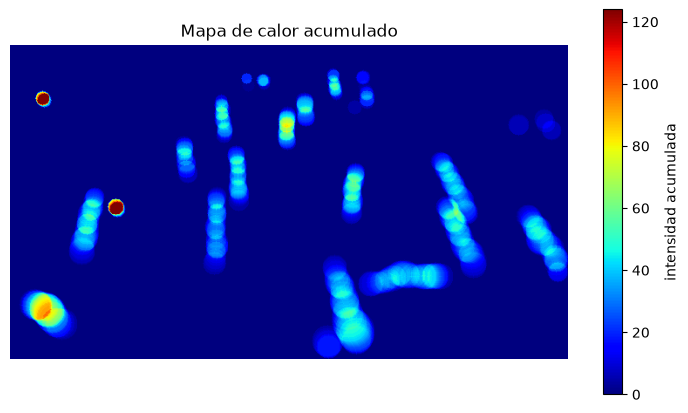

{'izq': 0.27, 'centro': 0.43, 'der': 0.3}


In [41]:
heat = solutions.Heatmap(model="yolo11n.pt", colormap=cv2.COLORMAP_JET, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                         show=False, verbose=False, device=DEVICE)
df3, seg = procesar_video(heat, VIDEO_CALLE, "eq3_heatmap.mp4")
mostrar_video("eq3_heatmap.mp4")
mapa = heat.heatmap.copy()                      # matriz acumulada (alto × ancho)
plt.figure(figsize=(9, 5)); plt.imshow(mapa, cmap="jet"); plt.colorbar(label="intensidad acumulada")
plt.title("Mapa de calor acumulado"); plt.axis("off"); plt.show()
# ¿En qué tercio del video (izquierda / centro / derecha) circula más gente?
tercios = np.array_split(mapa, 3, axis=1)
print({n: round(float(t.sum() / mapa.sum()), 2) for n, t in zip(["izq", "centro", "der"], tercios)})

In [42]:
# 🔧 Barrido obligatorio (métrica: % de calor en el centro)
def crear_heat(c, sz, tr):
    return solutions.Heatmap(model="yolo11n.pt", colormap=cv2.COLORMAP_JET, classes=[0], conf=c, imgsz=sz,
                             tracker=tr, show=False, verbose=False, device=DEVICE)
filas = []
for tr in ["bytetrack.yaml", "tracktrack.yaml"]:
    for sz in [320, 640]:
        for c in [0.15, 0.35, 0.6]:
            h = crear_heat(c, sz, tr); _, seg = procesar_video(h, VIDEO_CALLE)
            m = h.heatmap; filas.append(dict(tracker=tr, imgsz=sz, conf=c,
                                             pct_centro=round(float(np.array_split(m, 3, axis=1)[1].sum() / max(m.sum(), 1)), 2)))
pd.DataFrame(filas)

⚠️ 60 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.15, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.35, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


,tracker,imgsz,conf,pct_centro
0,bytetrack.yaml,320,0.15,0.51
1,bytetrack.yaml,320,0.35,0.73
2,bytetrack.yaml,320,0.60,1.00
3,bytetrack.yaml,640,0.15,0.44
4,bytetrack.yaml,640,0.35,0.43
5,bytetrack.yaml,640,0.60,0.45
6,tracktrack.yaml,320,0.15,0.00
7,tracktrack.yaml,320,0.35,0.00
8,tracktrack.yaml,320,0.60,0.00
9,tracktrack.yaml,640,0.15,0.36


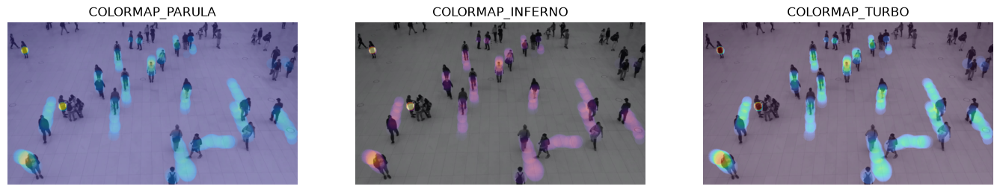

In [43]:
# Proyecto 3 (a): tres colormaps sobre el último frame
norm = cv2.normalize(mapa, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (n, cm) in zip(ax, [("PARULA", cv2.COLORMAP_PARULA), ("INFERNO", cv2.COLORMAP_INFERNO), ("TURBO", cv2.COLORMAP_TURBO)]):
    mezcla = cv2.addWeighted(fondo, 0.5, cv2.applyColorMap(norm, cm), 0.5, 0)
    a.imshow(cv2.cvtColor(mezcla, cv2.COLOR_BGR2RGB)); a.set_title(f"COLORMAP_{n}"); a.axis("off")
plt.show()

In [44]:
# Proyecto 3 (c): Heatmap con region=ZONA (cuenta cruces del borde del polígono)
heat_z = solutions.Heatmap(model="yolo11n.pt", colormap=cv2.COLORMAP_JET, region=ZONA, classes=[0], conf=0.25, imgsz=640,
                           tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
df3z, _ = procesar_video(heat_z, VIDEO_CALLE, "eq3_heatmap_zona.mp4")
print(f"Con region=ZONA → entradas={df3z.in_count.iloc[-1]}  salidas={df3z.out_count.iloc[-1]}")
tz = np.array_split(heat_z.heatmap, 3, axis=1)
print({n: round(float(t.sum() / heat_z.heatmap.sum()), 2) for n, t in zip(["izq", "centro", "der"], tz)})

Con region=ZONA → entradas=5  salidas=3
{'izq': 0.27, 'centro': 0.43, 'der': 0.3}


**✍️ Proyecto 3:** (a) Prueben 3 `colormap` distintos (`COLORMAP_PARULA`, `COLORMAP_INFERNO`, `COLORMAP_TURBO`). ¿Cuál comunica mejor a un gerente de tienda? (b) ¿El mapa cambia mucho con `conf`? ¿Por qué? (c) Agreguen `region=ZONA` y reporten el conteo. (d) ¿Qué decisión de negocio tomarían con este mapa?

### 💬 Respuesta Proyecto 3 — `Heatmap`
**(a) Colormaps:** `PARULA` es sobrio y uniforme, pero sobre un fondo gris las zonas frías se confunden con el fondo; `INFERNO` (negro→amarillo) funciona bien en impresión pero las zonas de poco tránsito casi no se ven sobre fondo oscuro; **`TURBO` comunica mejor**: contrasta con el fondo, distingue claramente los *puntos calientes* (rojo) de los corredores de paso (verde/azul) y es más uniforme perceptualmente que `JET`. Para un gerente de tienda elegiría `TURBO` con una barra de color.
**(b) ¿Cambia con `conf`?** A 640 px prácticamente **no**: el % de calor en el tercio central es 0.44 / 0.43 / 0.45 para conf=0.15/0.35/0.6 con bytetrack. A **320 px sí cambia mucho** (0.51 → 0.73 → 1.00) porque casi nadie supera el umbral, el mapa se forma con 1–3 personas y deja de ser representativo; con tracktrack @320 es 0.00 (no hay tracks). El cambio no es por `conf` en sí sino por **cuántas personas se detectan**.
**(c) `region=ZONA`:** el `Heatmap` también cuenta cruces de la región: **5 entradas y 3 salidas** (igual que `ObjectCounter` con polígono). El reparto del calor sigue siendo ≈ 27 % izquierda / **43 % centro** / 30 % derecha.
**(d) Decisión de negocio:** el **43 % de la circulación pasa por el tercio central**, por corredores bien definidos; colocaría ahí productos de alta rotación/promociones y personal de ayuda; las zonas frías (esquinas) son candidatas a reubicar mercancía o rediseñar el pasillo. También lo usaría para ubicar anaqueles sin bloquear el flujo y ajustar horarios de limpieza y personal.

## Proyecto 4 — `SpeedEstimator`: estimación de velocidad
Convierte el desplazamiento en píxeles a km/h usando `meter_per_pixel` (escala) y `fps`. **Sin calibración, el número no significa nada.**

Altura media de las personas en px: 51.1 → MPP sugerido ≈ 0.0332


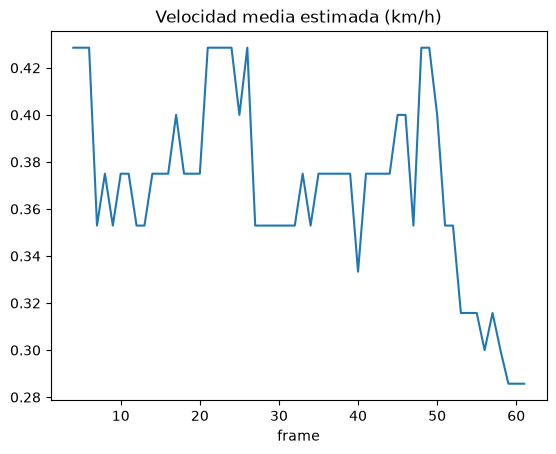

In [45]:
MPP = 0.01   # 🔧 metros por píxel: estímalo (ej. una persona mide ~1.7 m ≈ ¿cuántos px de alto?)
print("Altura media de las personas en px:", round(tracks[tracks.clase == "person"].h.median(), 1),
      "→ MPP sugerido ≈", round(1.7 / tracks[tracks.clase == "person"].h.median(), 4))
vel_sol = solutions.SpeedEstimator(model="yolo11n.pt", meter_per_pixel=MPP, fps=info_video(VIDEO_CALLE)["fps"],
                                   max_speed=60, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
ext_vel = lambda r: {"vel_media": np.mean(list(r.speed_dict.values())) if r.speed_dict else np.nan}
df4, seg = procesar_video(vel_sol, VIDEO_CALLE, "eq4_velocidad.mp4", extra=ext_vel)
mostrar_video("eq4_velocidad.mp4")
df4.vel_media.plot(title="Velocidad media estimada (km/h)"); plt.xlabel("frame"); plt.show()

In [46]:
# Calibración de MPP (Proyecto 4 a): velocidad ∝ MPP → mido con una sonda y escalo hasta ~4.5 km/h (marcha humana)
ext_vel = lambda r: {"vel_media": np.mean(list(r.speed_dict.values())) if r.speed_dict else np.nan}
def media_vel(mpp, fps, max_speed=1000):
    s = solutions.SpeedEstimator(model="yolo11n.pt", meter_per_pixel=mpp, fps=fps, max_speed=max_speed, classes=[0], conf=0.25,
                                 imgsz=640, tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
    d, _ = procesar_video(s, VIDEO_CALLE, extra=ext_vel)
    return d, d.vel_media.mean()

_, v_sonda = media_vel(0.1, 30)
MPP_CAL = round(0.1 * 4.5 / v_sonda, 4)
print(f"Sonda MPP=0.1 → {v_sonda:.1f} km/h | MPP calibrado = {MPP_CAL} (sugerido por altura de persona: {round(1.7 / tracks[tracks.clase == 'person'].h.median(), 4)})")
filas = []
for etiqueta, mpp, fps in [("MPP original 0.01", 0.01, 30), ("MPP calibrado, fps=30", MPP_CAL, 30),
                           ("MPP calibrado, fps=15 (incorrecto)", MPP_CAL, 15), ("MPP calibrado, fps=60 (incorrecto)", MPP_CAL, 60)]:
    _, v = media_vel(mpp, fps)
    filas.append(dict(config=etiqueta, vel_media_kmh=round(v, 2)))
MPP = MPP_CAL   # el barrido obligatorio de abajo usa la escala calibrada
pd.DataFrame(filas)

Sonda MPP=0.1 → 7.9 km/h | MPP calibrado = 0.0572 (sugerido por altura de persona: 0.0332)


,config,vel_media_kmh
0,MPP original 0.01,0.37
1,"MPP calibrado, fps=30",4.24
2,"MPP calibrado, fps=15 (incorrecto)",1.93
3,"MPP calibrado, fps=60 (incorrecto)",9.03


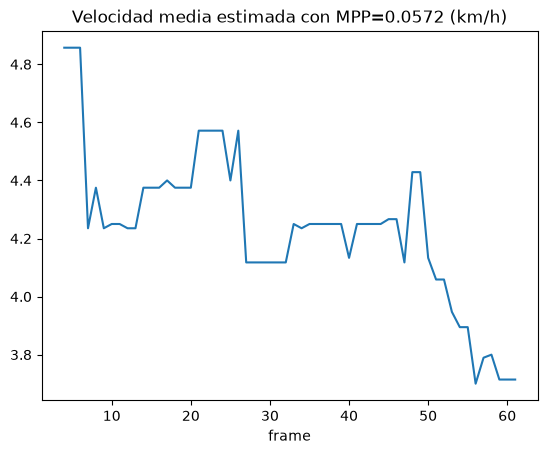

In [47]:
# Video con la calibración final (Proyecto 4)
vel_cal = solutions.SpeedEstimator(model="yolo11n.pt", meter_per_pixel=MPP, fps=info_video(VIDEO_CALLE)["fps"], max_speed=60,
                                   classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
df4c, _ = procesar_video(vel_cal, VIDEO_CALLE, "eq4_velocidad_calibrada.mp4", extra=ext_vel)
mostrar_video("eq4_velocidad_calibrada.mp4")
df4c.vel_media.plot(title=f"Velocidad media estimada con MPP={MPP} (km/h)"); plt.xlabel("frame"); plt.show()

In [48]:
# 🔧 Barrido obligatorio
b4 = barrido_solucion(lambda c, sz, tr: solutions.SpeedEstimator(model="yolo11n.pt", meter_per_pixel=MPP, fps=30,
                      max_speed=60, classes=[0], conf=c, imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: round(d.vel_media.mean(), 1), extra=ext_vel)
b4

⚠️ 60 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.15, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.35, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,6.2,71.4
1,bytetrack,320,0.35,9.3,72.3
2,bytetrack,320,0.60,NaN,78.4
3,bytetrack,640,0.15,3.9,33.7
4,bytetrack,640,0.35,5.6,33.4
5,bytetrack,640,0.60,6.2,34.8
6,tracktrack,320,0.15,NaN,62.8
7,tracktrack,320,0.35,NaN,66.6
8,tracktrack,320,0.60,NaN,66.2
9,tracktrack,640,0.15,7.3,31.1


**✍️ Proyecto 4:** (a) Una persona camina a ~4–5 km/h. Calibra `meter_per_pixel` hasta que la estimación sea realista y explica tu método. (b) ¿Por qué la perspectiva (personas lejos se ven pequeñas) hace que **un solo** `meter_per_pixel` sea un error? (c) ¿Qué pasa si declaras `fps` incorrecto? (d) ¿Qué harían para usar esto en una calle real con autos?

### 💬 Respuesta Proyecto 4 — `SpeedEstimator`
**(a) Calibración:** en `SpeedEstimator` la velocidad es **proporcional a `meter_per_pixel`** (km/h = px × m/px / Δt × 3.6). Método: medí la velocidad media con una *sonda* `MPP=0.1` → **7.9 km/h**, y escalé: `MPP = 0.1 × 4.5 / 7.9 = 0.0572`. Con ese valor la media es **4.24 km/h** (marcha humana ≈ 4–5 km/h; parte de la diferencia viene de que la solución trunca cada velocidad a entero). La estimación "por altura" (1.7 m / 51 px = 0.0332) queda más baja porque en una vista cenital/oblicua la persona se ve **acortada**: su altura en píxeles no representa la escala del suelo. Con `MPP=0.01` (valor original) la media era 0.37 km/h, un número sin sentido. El barrido y los videos siguientes usan `MPP=0.0572` (con ese valor el barrido da ≈ 4–6 km/h con bytetrack @640 px y 7 km/h con tracktrack @640 px; a 320 px casi no hay tracks).
**(b) Perspectiva:** la escala (m/píxel) **no es constante**: un píxel en el fondo (lejos) cubre muchos más metros que uno cerca de la cámara. Un solo `MPP` subestima la velocidad de quien está lejos y sobreestima la de quien está cerca. La solución es una **homografía al plano del suelo** o un MPP por franja de la imagen.
**(c) `fps` incorrecto:** la velocidad es **directamente proporcional al `fps`** declarado. Medido con el `MPP` calibrado: `fps=15` → **1.93 km/h** (la mitad) y `fps=60` → **9.03 km/h** (el doble) frente a 4.24 km/h con 30 fps.
**(d) Calles con autos:** calibrar la escala con referencias de longitud conocida (ancho de carril, rayas del pavimento, largo de un auto ≈ 4.5 m) y usar homografía, cámara fija y elevada, fps reales de la fuente, `max_speed` acorde (≥ 120 km/h), un historial más largo (`max_hist`) y validar contra radar/GPS; filtrar por clase (`car`, `truck`, ...) y medir en tramos de trayectoria casi recta.

## Proyecto 5 — `RegionCounter` y `QueueManager`: ocupación de zonas y filas
`RegionCounter` acepta **varias** zonas con nombre; `QueueManager` cuenta cuántos objetos hay dentro de la región de la fila.

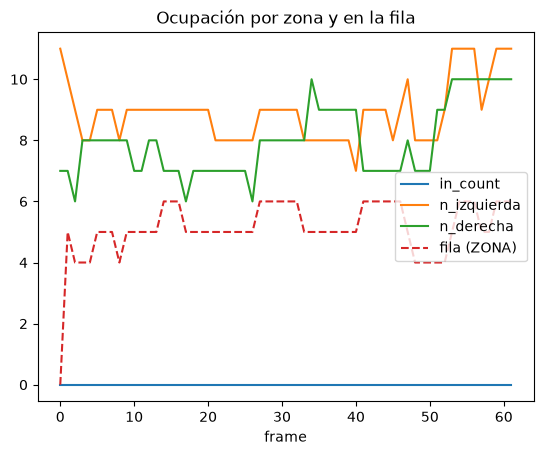

In [49]:
ZONAS = {"izquierda": [(0, 0), (W // 2, 0), (W // 2, H), (0, H)],
         "derecha":   [(W // 2, 0), (W, 0), (W, H), (W // 2, H)]}
reg = solutions.RegionCounter(model="yolo11n.pt", region=ZONAS, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                              show=False, verbose=False, device=DEVICE)
ext_reg = lambda r: {f"n_{k}": v for k, v in r.region_counts.items()}
df5, seg = procesar_video(reg, VIDEO_CALLE, "eq5_regiones.mp4", extra=ext_reg)
mostrar_video("eq5_regiones.mp4")

fila = solutions.QueueManager(model="yolo11n.pt", region=ZONA, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                              show=False, verbose=False, device=DEVICE)
df5q, _ = procesar_video(fila, VIDEO_CALLE, "eq5_fila.mp4")
mostrar_video("eq5_fila.mp4")

ax = df5.filter(like="n_").plot(title="Ocupación por zona y en la fila")
df5q.queue_count.plot(ax=ax, ls="--", label="fila (ZONA)"); ax.legend(); plt.xlabel("frame"); plt.show()

In [50]:
# 🔧 Barrido obligatorio (métrica: ocupación máxima de la fila)
b5 = barrido_solucion(lambda c, sz, tr: solutions.QueueManager(model="yolo11n.pt", region=ZONA, classes=[0], conf=c,
                      imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: d.queue_count.max())
b5

⚠️ 60 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.15, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.35, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,4,70.8
1,bytetrack,320,0.35,2,76.7
2,bytetrack,320,0.60,0,76.4
3,bytetrack,640,0.15,6,32.2
4,bytetrack,640,0.35,6,33.5
5,bytetrack,640,0.60,5,35.2
6,tracktrack,320,0.15,0,55.5
7,tracktrack,320,0.35,0,63.1
8,tracktrack,320,0.60,0,66.8
9,tracktrack,640,0.15,3,31.0


In [51]:
# Proyecto 5 (a): 3 zonas con sentido (tercios): ENTRADA (izq.), PASILLO (centro), CAJA (der.)
ZONAS3 = {"entrada": [(0, 0), (W // 3, 0), (W // 3, H), (0, H)],
          "pasillo": [(W // 3, 0), (2 * W // 3, 0), (2 * W // 3, H), (W // 3, H)],
          "caja":    [(2 * W // 3, 0), (W, 0), (W, H), (2 * W // 3, H)]}
reg3 = solutions.RegionCounter(model="yolo11n.pt", region=ZONAS3, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                               show=False, verbose=False, device=DEVICE)
df5z, _ = procesar_video(reg3, VIDEO_CALLE, "eq5_zonas3.mp4", extra=ext_reg)
oc = df5z.filter(regex="^n_")
display(pd.DataFrame({"max": oc.max(), "media": oc.mean().round(1), "p90": oc.quantile(0.9)}))
# Proyecto 5 (c): umbral de alerta para abrir otra caja (percentil 90 de la fila ZONA)
print("Fila ZONA → máx:", df5q.queue_count.max(), "| media:", round(df5q.queue_count.mean(), 1),
      "| p90:", df5q.queue_count.quantile(0.9), "→ umbral de alerta sugerido =", int(np.ceil(df5q.queue_count.quantile(0.9))))

,max,media,p90
n_entrada,5,4.5,5.0
n_pasillo,13,8.5,13.0
n_caja,5,4.0,5.0


Fila ZONA → máx: 6 | media: 5.1 | p90: 6.0 → umbral de alerta sugerido = 6


**✍️ Proyecto 5:** (a) Diseñen 3 zonas con sentido (entrada, pasillo, caja) y reporten la ocupación máxima y media de cada una. (b) ¿Una persona que está *sobre el borde* de dos zonas se cuenta en ambas? Revisen con qué punto de la caja decide la solución. (c) ¿Qué umbral de ocupación dispararía una alerta para abrir otra caja?

### 💬 Respuesta Proyecto 5 — `RegionCounter` / `QueueManager`
**(a) Zonas con sentido** (tercios verticales de la imagen: **entrada** = izquierda, **pasillo** = centro, **caja** = derecha):

| zona | ocupación máxima | media | p90 |
|---|---|---|---|
| entrada | 5 | 4.5 | 5 |
| pasillo | 13 | 8.5 | 13 |
| caja | 5 | 4.0 | 5 |

El pasillo concentra a la mayoría (máx. 13 personas a la vez).
**(b) Persona en el borde de dos zonas:** `RegionCounter` y `QueueManager` deciden con **el centro de la caja** (`(x0+x1)/2, (y0+y1)/2`) y la prueba `polygon.contains(centro)`; por eso una persona se cuenta en **una sola** zona (la que contiene el centro de su caja) si las zonas no se traslapan; un punto *exactamente* sobre el borde da `contains` falso para ambas, y si las zonas se **traslapan** sí se cuenta en las dos.
**(c) Umbral de alerta:** la fila (`ZONA`) tuvo máx. 6, media 5.1 y p90 6 en 2 s de video; propongo **alerta cuando la fila alcance ≥ 6 personas durante varios frames seguidos** (≈ percentil 90 de la ocupación normal) para abrir otra caja. Con una grabación más larga habría que calibrar el umbral con el percentil 90–95 y añadir **persistencia** (p. ej. > 30 s) para no alertar por picos.

## Proyecto 6 — `TrackZone` + `ObjectBlurrer`: análisis en zona y privacidad
`TrackZone` solo detecta y sigue **dentro** de la región (ahorra cómputo). `ObjectBlurrer` difumina los objetos detectados: un primer paso de **anonimización**

In [52]:
zona = solutions.TrackZone(model="yolo11n.pt", region=ZONA, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                           show=False, verbose=False, device=DEVICE)
df6, seg_zona = procesar_video(zona, VIDEO_CALLE, "eq6_trackzone.mp4")
mostrar_video("eq6_trackzone.mp4")

blur = solutions.ObjectBlurrer(model="yolo11n.pt", blur_ratio=0.5, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                               show=False, verbose=False, device=DEVICE)
df6b, seg_blur = procesar_video(blur, VIDEO_CALLE, "eq6_blur.mp4")
mostrar_video("eq6_blur.mp4")
print(f"Tracks en zona (media): {df6.total_tracks.mean():.1f} | en toda la imagen: {df6b.total_tracks.mean():.1f}")
print(f"Tiempo TrackZone: {seg_zona:.1f}s | Tiempo imagen completa: {seg_blur:.1f}s")

Tracks en zona (media): 5.7 | en toda la imagen: 16.9
Tiempo TrackZone: 1.7s | Tiempo imagen completa: 1.7s


In [53]:
# 🔧 Barrido obligatorio — ¿con qué conf se "escapa" alguien sin difuminar?
b6 = barrido_solucion(lambda c, sz, tr: solutions.ObjectBlurrer(model="yolo11n.pt", blur_ratio=0.5, classes=[0], conf=c,
                      imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: (d.total_tracks == 0).sum())   # frames sin ninguna persona difuminada
b6

⚠️ 60 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.15, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.35, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,0,80.2
1,bytetrack,320,0.35,0,79.7
2,bytetrack,320,0.60,60,75.2
3,bytetrack,640,0.15,0,33.4
4,bytetrack,640,0.35,0,34.3
5,bytetrack,640,0.60,0,34.7
6,tracktrack,320,0.15,62,64.0
7,tracktrack,320,0.35,62,63.5
8,tracktrack,320,0.60,62,65.5
9,tracktrack,640,0.15,0,31.4


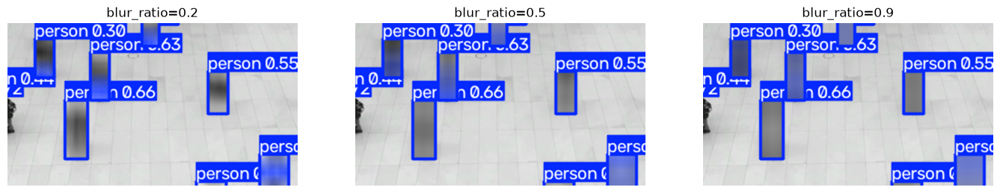

In [54]:
# Proyecto 6 (b): blur_ratio 0.2 / 0.5 / 0.9 (frame 30, recorte de la zona central ×2)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, br in zip(ax, [0.2, 0.5, 0.9]):
    bl = solutions.ObjectBlurrer(model="yolo11n.pt", blur_ratio=br, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                                 show=False, verbose=False, device=DEVICE)
    cap = cv2.VideoCapture(VIDEO_CALLE); nivel = LOGGER.level; LOGGER.setLevel(logging.ERROR)
    for _ in range(31):
        r = bl(cap.read()[1])
    cap.release(); LOGGER.setLevel(nivel)
    recorte = r.plot_im[90:270, 160:480]
    a.imshow(cv2.cvtColor(cv2.resize(recorte, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC), cv2.COLOR_BGR2RGB))
    a.set_title(f"blur_ratio={br}"); a.axis("off")
plt.show()

In [55]:
# Proyecto 6 (c): TrackZone vs imagen completa, repetido 3 veces para promediar el ruido de tiempo
tz_t, bl_t = [], []
for _ in range(3):
    z = solutions.TrackZone(model="yolo11n.pt", region=ZONA, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                            show=False, verbose=False, device=DEVICE)
    tz_t.append(procesar_video(z, VIDEO_CALLE)[1])
    b_ = solutions.ObjectBlurrer(model="yolo11n.pt", blur_ratio=0.5, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                                 show=False, verbose=False, device=DEVICE)
    bl_t.append(procesar_video(b_, VIDEO_CALLE)[1])
print(f"TrackZone: {np.mean(tz_t):.2f}s (±{np.std(tz_t):.2f}) | imagen completa: {np.mean(bl_t):.2f}s (±{np.std(bl_t):.2f})")

TrackZone: 1.80s (±0.02) | imagen completa: 1.87s (±0.05)


**✍️ P6:** (a) Para anonimizar, ¿qué es peor: un falso positivo (difuminar algo que no es persona) o un falso negativo (dejar una cara visible)? Con base en eso, ¿qué `conf` eligen? (b) Prueben `blur_ratio` 0.2, 0.5 y 0.9: ¿desde qué valor ya no se reconoce a la persona? (c) ¿Por qué `TrackZone` puede ser más rápido? ¿Lo confirman sus tiempos? (d) ¿Difuminar el cuerpo completo es suficiente para cumplir con privacidad? ¿Qué más se podría identificar (ropa, forma de caminar)?

### 💬 Respuesta Proyecto 6 — `TrackZone` + `ObjectBlurrer`
**(a) FP vs FN:** para anonimizar es **peor el falso negativo** (dejar una persona sin difuminar = filtración de identidad); un falso positivo sólo difumina de más. Se elige un `conf` **bajo** (≈ **0.15 – 0.25**) y **`imgsz=640`**. En el barrido de la celda anterior: a 640 px ningún frame queda sin persona difuminada (0 frames con bytetrack ni tracktrack); pero a **320 px**, con bytetrack y `conf=0.6` quedan **60 de 62 frames** sin difuminar a nadie, y con tracktrack **62 de 62** con cualquier `conf` (sus umbrales de 0.6–0.7 descartan detecciones débiles). Para anonimización no deberían usarse tracktrack ni 320 px.
**(b) `blur_ratio`:** con **0.2** todavía se ve la silueta y el tono de la ropa; con **0.5** ya no se distingue ningún detalle (sólo una mancha) y con **0.9** es un bloque gris uniforme. En este video (personas de ~50 px) ya con **0.5** no se reconoce a nadie; con video de más resolución se debe usar ≥ 0.5–0.7 y verificarlo visualmente.
**(c) ¿`TrackZone` es más rápido?** En teoría hace menos trabajo de tracking (sólo sigue lo que está dentro de la zona: **5.7 tracks medios vs 16.9** en toda la imagen), pero **los tiempos no lo confirman**: 1.80 s (±0.02) vs 1.87 s (±0.05), prácticamente iguales (~4 %). Razón: `TrackZone` aplica una **máscara sobre el frame completo** y el detector corre igual sobre toda la imagen; sólo ahorra el tracking/post-proceso. En un video corto y pequeño el costo lo domina el detector. El ahorro sería real con un recorte (*crop*) del ROI antes de detectar.
**(d) ¿Basta difuminar el cuerpo?** No. Persisten **identificadores indirectos**: ropa y accesorios (mochilas, tatuajes), **forma de caminar** (*gait*), estatura/complexión, el **contexto** (lugar, hora, con quién va) y los **fallos del detector** (una persona sin difuminar en un frame). Además hay que cuidar **dónde se guarda el video original**, minimizar datos (guardar sólo conteos agregados), avisar/obtener consentimiento y cumplir la normativa de datos personales (p. ej. LFPDPPP en México, GDPR en la UE).

In [56]:
# Pregunta 3: ¿por qué tracktrack @320 no recupera objetos al bajar conf? → el tracker filtra DESPUÉS del detector
cfg_tt = yaml.safe_load(open(os.path.join(os.path.dirname(ultralytics.__file__), "cfg", "trackers", "tracktrack.yaml")))
print({k: cfg_tt[k] for k in ["track_high_thresh", "track_low_thresh", "new_track_thresh", "min_track_len"]})
filas = []
for tr_ in ["bytetrack.yaml", "tracktrack.yaml"]:
    for sz, c in [(320, 0.6), (320, 0.15), (640, 0.15)]:
        d, seg = procesar_video(solutions.ObjectCounter(model="yolo11n.pt", region=LINEA, classes=[0], conf=c, imgsz=sz, tracker=tr_,
                                show=False, verbose=False, device=DEVICE), VIDEO_CALLE)
        filas.append(dict(tracker=tr_.replace(".yaml", ""), imgsz=sz, conf=c, tracks_medios_por_frame=round(d.total_tracks.mean(), 1),
                          tracks_max=int(d.total_tracks.max()), fps_proc=round(len(d) / seg, 1)))
pd.DataFrame(filas)

{'track_high_thresh': 0.6, 'track_low_thresh': 0.25, 'new_track_thresh': 0.7, 'min_track_len': 3}


⚠️ 60 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.6, imgsz=320)


⚠️ 62 de 62 frames sin ningún objeto seguido (conf=0.15, imgsz=320)


,tracker,imgsz,conf,tracks_medios_por_frame,tracks_max,fps_proc
0,bytetrack,320,0.60,0.0,1,76.0
1,bytetrack,320,0.15,6.2,8,64.3
2,bytetrack,640,0.15,19.7,22,34.1
3,tracktrack,320,0.60,0.0,0,68.2
4,tracktrack,320,0.15,0.0,0,63.7
5,tracktrack,640,0.15,5.4,7,31.1


In [57]:
# Pregunta 4: FPS de la configuración final (ObjectCounter, bytetrack, conf=0.25, iou=0.7, classes=[0]) a 320 y 640 px
filas = []
for sz in [320, 640]:
    d, seg = procesar_video(solutions.ObjectCounter(model="yolo11n.pt", region=LINEA, classes=[0], conf=0.25, iou=0.7, imgsz=sz,
                            tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE), VIDEO_CALLE)
    filas.append(dict(imgsz=sz, fps=round(len(d) / seg, 1), cuenta_total=int(d.in_count.iloc[-1] + d.out_count.iloc[-1])))
display(pd.DataFrame(filas))
print("Barrido P1 (fps_proc medio por tracker/imgsz):"); display(b1.groupby(["tracker", "imgsz"]).fps_proc.mean().unstack())

,imgsz,fps,cuenta_total
0,320,72.5,3
1,640,34.2,4


Barrido P1 (fps_proc medio por tracker/imgsz):


imgsz,320,640
tracker,,
bytetrack,72.666667,30.5
tracktrack,63.433333,31.0


##EXTRA
- `solutions.VisionEye(model="yolo11n.pt", vision_point=(50, 50))`: traza líneas desde un "ojo" a cada objeto.
- Reemplazar `yolo11n.pt` por `yolo11s.pt` (≈ 19 MB, **solo si el internet lo permite**) y comparar mAP y FPS.
- Implementar el color con K-means dentro de cada caja y comparar contra el método HSV.

## ✍️ Preguntas
1. Presenten una **tabla con su configuración final** (`conf`, `iou`, `imgsz`, `classes`, `tracker` y parámetros propios de su solución) y **una línea de justificación por parámetro**, citando su barrido.
2. ¿Cuál fue el mayor error que vieron en su solución (conteo doble, ID perdido, persona no detectada…)? ¿Fue culpa del **detector** (2.1) o del **tracker** (2.4)? ¿Cómo lo distinguieron?
3. En el barrido, con `tracktrack` e `imgsz=320`, bajar `conf` de 0.6 a 0.15 **no** recupera objetos. ¿Por qué? (Pista: revisen `track_high_thresh` y `new_track_thresh` en B3: el tracker filtra *después* del detector.)
4. ¿Cuántos FPS logra su configuración final? ¿Alcanzaría para tiempo real (≥ 25 FPS)? ¿Qué sacrificarían para lograrlo?

## Entregable
1. Este notebook ejecutado completo, con las celdas ✍️ respondidas, compartido como enlace de Colab (y `.ipynb` en Moodle).
2. Los videos de salida de su Proyecto (`eqN_*.mp4`).

---
## ✍️ Respuestas a las preguntas finales

**1. Configuración final** (proyecto principal: `ObjectCounter`; el resto de las soluciones usa la misma base):

| parámetro | valor | justificación (citando el barrido) |
|---|---|---|
| `conf` | **0.25** | A 640 px el conteo es estable (4) entre `conf` 0.15 y 0.35 y baja a 3 con 0.6; 0.25 evita los falsos positivos de 0.1 sin perder personas. Para *anonimizar* se usa 0.15 (el FN es más caro). |
| `iou` | **0.7** | `iou=0.95` multiplicó las cajas ×3 (38 → 122 en la calle) y `iou=0.3` perdió 5 personas pegadas (38 → 33). |
| `imgsz` | **640** | A 320 px casi no se ve a nadie (bytetrack: 0–3 cruces; tracktrack: 0; 60–62 de 62 frames sin tracks con `conf` alto). Cuesta ~×2 en fps, pero las personas miden ~50 px. |
| `classes` | **[0]** (persona) | Elimina ruido de otras clases y cómputo. |
| `tracker` | **bytetrack** | TrackTrack ignora a las personas lejanas (7 IDs frente a 21 simultáneas; 2 cruces frente a 4). |
| `region` | **línea horizontal y=H/2** | La vertical da 0 cruces: el flujo de gente es vertical, así que la línea debe ser perpendicular. |
| Otros | AIGym `up=140°`, `down=80°`, `kpts=[6,8,10]`; Speed `MPP=0.0572`, `fps=30`; Blur `blur_ratio≥0.5`, `conf=0.15` | Ver la respuesta de cada proyecto. |

**2. Mayor error observado:** (i) **personas pegadas fusionadas en un solo ID** (el grupo del ID 14 junto a la línea → subconteo) y (ii) **personas no seguidas** (TrackTrack y/o 320 px). Lo primero es culpa **del detector (2.1)** y de NMS (cajas muy traslapadas con `iou=0.7`), no del tracker; lo segundo tiene dos causas distintas. Cómo se distinguió: se corrió **el detector solo** (`model(frame)` en A5): ve 38 personas en el frame 30 con `conf=0.05`, o sea el detector sí encuentra a la gente; cuando el **tracker** no entrega IDs con las mismas detecciones (TrackTrack: 7 IDs a 640 px y `tracks_max=0` a 320 px) el filtro es del tracker (2.4). A 320 px, en cambio, el problema es del **detector** (pocos píxeles por persona → confianza baja).

**3. `tracktrack` e `imgsz=320`: ¿por qué bajar `conf` de 0.6 a 0.15 no recupera objetos?** Porque el tracker **filtra después del detector**. TrackTrack exige `track_high_thresh=0.6` para asociar y `new_track_thresh=0.7` para **crear** un ID nuevo (`track_low_thresh=0.25` sólo ayuda a mantener pistas ya existentes). A 320 px las personas pequeñas casi nunca superan 0.6–0.7 de confianza, así que aunque `conf=0.15` deje pasar más cajas del detector, el tracker las descarta. Medido: tracktrack @320 → **0 tracks máximos con `conf` 0.6 y con 0.15**; bytetrack @320 con `conf=0.15` → 8 tracks máximos (umbrales de 0.25).

**4. FPS (CPU Apple M3 Max, sin GPU):** `ObjectCounter` + bytetrack: **≈ 34 FPS a 640 px y ≈ 72 FPS a 320 px**. A 640 px **sí supera 25 FPS** (con poco margen, ~1.3×) y a 320 px con holgura; en una GPU T4 de Colab sería mayor. En una máquina más débil se sacrificaría **resolución** (pero se pierden personas lejanas), **saltar frames** (`vid_stride=2`), **ROI con recorte** o exportar a **ONNX/TensorRT/CoreML con FP16**; el modelo ya es el más pequeño (`yolo11n`).

---
### Notas sobre el entorno de ejecución
- Ejecutado localmente con **uv** (Python 3.11, `ultralytics 8.4.176`, CPU), no en Colab/GPU: las celdas de `google.colab` (subida de video propio) siguen comentadas y la celda de `pip install` se sustituyó por la gestión de dependencias con `uv`.
- Los videos de salida (`eq1_*.mp4` ... `eq6_*.mp4`) quedan en la carpeta del proyecto.
- Los tiempos/FPS mencionados son de una corrida concreta y varían unos puntos entre ejecuciones.